# Análisis de ventas de videojuegos – Tienda Ice

**Contexto:** Ice es una tienda online que vende videojuegos en todo el mundo. Es diciembre de 2016 y se está planificando la campaña publicitaria de 2017.

**Objetivo:** identificar los patrones que determinan si un videojuego tiene éxito (plataforma, género, reseñas, clasificación ESRB y región) para detectar proyectos prometedores y orientar la inversión publicitaria.

**Estructura del análisis:**

1. Carga de datos e información general
2. Preparación de datos
3. Análisis exploratorio
4. Perfil de usuario por región (NA, UE, JP)
5. Pruebas de hipótesis
6. Conclusión general


## Paso 1. Carga de datos e información general


In [1]:
# Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as st

In [2]:
# Carga del dataset: ruta de la plataforma TripleTen o ruta local
try:
    df = pd.read_csv('/datasets/games.csv')
except FileNotFoundError:
    df = pd.read_csv('games.csv')

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  str    
 1   Platform         16715 non-null  str    
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  str    
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  str    
 10  Rating           9949 non-null   str    
dtypes: float64(6), str(5)
memory usage: 1.4 MB


In [4]:
df.head(10)

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN
5,Tetris,GB,1989.0,Puzzle,23.20,2.26,4.22,0.58,NaN,NaN,NaN
6,New Super Mario Bros.,DS,2006.0,Platform,11.28,9.14,6.50,2.88,89.0,8.5,E
7,Wii Play,Wii,2006.0,Misc,13.96,9.18,2.93,2.84,58.0,6.6,E
8,New Super Mario Bros. Wii,Wii,2009.0,Platform,14.44,6.94,4.70,2.24,87.0,8.4,E
9,Duck Hunt,NES,1984.0,Shooter,26.93,0.63,0.28,0.47,NaN,NaN,NaN


In [5]:
# Valores ausentes: cantidad y porcentaje por columna
ausentes = pd.DataFrame({
    'ausentes': df.isna().sum(),
    'porcentaje': (df.isna().mean() * 100).round(2)
}).sort_values('porcentaje', ascending=False)

ausentes

,ausentes,porcentaje
Critic_Score,8578,51.32
Rating,6766,40.48
User_Score,6701,40.09
Year_of_Release,269,1.61
Name,2,0.01
Genre,2,0.01
Platform,0,0.00
JP_sales,0,0.00
EU_sales,0,0.00
NA_sales,0,0.00


In [6]:
print('Duplicados explícitos:', df.duplicated().sum())

Duplicados explícitos: 0


In [7]:
df.describe()

,Year_of_Release,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score
count,16446.000000,16715.000000,16715.000000,16715.000000,16715.000000,8137.000000
mean,2006.484616,0.263377,0.145060,0.077617,0.047342,68.967679
std,5.877050,0.813604,0.503339,0.308853,0.186731,13.938165
min,1980.000000,0.000000,0.000000,0.000000,0.000000,13.000000
25%,2003.000000,0.000000,0.000000,0.000000,0.000000,60.000000
50%,2007.000000,0.080000,0.020000,0.000000,0.010000,71.000000
75%,2010.000000,0.240000,0.110000,0.040000,0.030000,79.000000
max,2016.000000,41.360000,28.960000,10.220000,10.570000,98.000000


In [8]:
# Valores no numéricos dentro de User_Score
df['User_Score'].value_counts().head(5)

User_Score
tbd    2424
7.8     324
8       290
8.2     282
8.3     254
Name: count, dtype: int64

### **Observaciones iniciales**

- El dataset tiene 16.715 registros y 11 columnas.
- Nombres de columnas: mezclan mayúsculas y minúsculas (`NA_sales`, `Critic_Score`). Se pasarán a minúsculas para trabajar de forma consistente.
- Tipos de datos incorrectos:
  - `Year_of_Release` es `float` cuando representa un año entero.
  - `User_Score` es texto (`object/str`) porque contiene el valor **`'tbd'`** (_to be determined_), que impide que pandas lo lea como número.
- Valores ausentes: `Critic_Score` (~51 %), `Rating` (~40 %) y `User_Score` (~40 %) concentran la mayoría. `Year_of_Release` tiene 269 (1,6 %) y `Name`/`Genre` solo 2.
- Duplicados: no hay duplicados explícitos; se revisarán duplicados implícitos (mismo juego, plataforma y año).
- Las ventas tienen mediana muy baja frente a su máximo (p. ej. `NA_sales`: mediana 0,08 vs. máximo 41,36): la distribución es **muy asimétrica**, con pocos _best-sellers_ y muchos juegos de ventas bajas.


## Paso 2. Preparación de datos


### 2.1 Nombres de columnas


In [9]:
df.columns = df.columns.str.strip().str.lower()
df.columns

Index(['name', 'platform', 'year_of_release', 'genre', 'na_sales', 'eu_sales',
       'jp_sales', 'other_sales', 'critic_score', 'user_score', 'rating'],
      dtype='str')

### 2.2 Duplicados implícitos


In [10]:
# Mismo juego, en la misma plataforma y el mismo año
df[df.duplicated(subset=['name', 'platform', 'year_of_release'], keep=False)]

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
604,Madden NFL 13,PS3,2012.0,Sports,2.11,0.22,0.00,0.23,83.0,5.5,E
659,NaN,GEN,1993.0,NaN,1.78,0.53,0.00,0.08,NaN,NaN,NaN
14244,NaN,GEN,1993.0,NaN,0.00,0.00,0.03,0.00,NaN,NaN,NaN
16230,Madden NFL 13,PS3,2012.0,Sports,0.00,0.01,0.00,0.00,83.0,5.5,E


Aparecen dos casos:

- **`Madden NFL 13` (PS3, 2012)** está registrado dos veces, al parecer es un duplicado donde solo se conserva el primer registro.
- Dos filas **sin nombre ni género** (plataforma GEN, 1993). No aportan información útil para el análisis (no sabemos qué juego ni de qué género son), por lo que se eliminan. Representan el 0,01 % de los datos.


In [11]:
df = df.drop_duplicates(
    subset=['name', 'platform', 'year_of_release'], keep='first')
df = df.dropna(subset=['name', 'genre']).reset_index(drop=True)
print('Registros tras la limpieza:', len(df))

Registros tras la limpieza: 16712


### 2.3 `year_of_release`: valores ausentes y tipo de dato


In [12]:
df[df['year_of_release'].isna()].head(10)

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
183,Madden NFL 2004,PS2,NaN,Sports,4.26,0.26,0.01,0.71,94.0,8.5,E
377,FIFA Soccer 2004,PS2,NaN,Sports,0.59,2.36,0.04,0.51,84.0,6.4,E
456,LEGO Batman: The Videogame,Wii,NaN,Action,1.80,0.97,0.00,0.29,74.0,7.9,E10+
475,wwe Smackdown vs. Raw 2006,PS2,NaN,Fighting,1.57,1.02,0.00,0.41,NaN,NaN,NaN
609,Space Invaders,2600,NaN,Shooter,2.36,0.14,0.00,0.03,NaN,NaN,NaN
627,Rock Band,X360,NaN,Misc,1.93,0.33,0.00,0.21,92.0,8.2,T
657,Frogger's Adventures: Temple of the Frog,GBA,NaN,Adventure,2.15,0.18,0.00,0.07,73.0,tbd,E
677,LEGO Indiana Jones: The Original Adventures,Wii,NaN,Action,1.51,0.61,0.00,0.21,78.0,6.6,E10+
718,Call of Duty 3,Wii,NaN,Shooter,1.17,0.84,0.00,0.23,69.0,6.7,T
804,Rock Band,Wii,NaN,Misc,1.33,0.56,0.00,0.20,80.0,6.3,T


Probablemente al recopilar la información de fuentes externas varios de estos juegos tienen el año justo en la columna `FIFA Soccer 2004`, `Madden NFL 2004`. El dato si exioste pero no se registró correctamente.

Lo mejor a realizar es eliminar estas filas, ya que, no todas son posibles tener la información del año, además solo son el 1.6% del total. Rellenar esos faltantes con la mediana distorsionaría completamente el análisis temporal.

Se convierte a **`entero`** no a `datetime`, porque solo tenemos el año. Un dato tipo _dt_ crearía fechas ficticias complicando las agrupaciones y filtrado.


In [13]:
df = df.dropna(subset=['year_of_release'])
df['year_of_release'] = df['year_of_release'].astype('Int64')
df['year_of_release'].describe()

count        16443.0
mean     2006.485921
std         5.875546
min           1980.0
25%           2003.0
50%           2007.0
75%           2010.0
max           2016.0
Name: year_of_release, dtype: Float64

### 2.4 `user_score`: el valor 'tbd' y el tipo de dato


In [14]:
print('Registros con tbd:', (df['user_score'] == 'tbd').sum())
df[df['user_score'] == 'tbd']['year_of_release'].value_counts()

Registros con tbd: 2376


year_of_release
2009    405
2010    331
2008    326
2011    217
2007    192
2002    192
2006    124
2005    121
2004    107
2003     95
2001     82
2000     43
2015     38
2016     34
2012     24
2014     21
2013     15
1999      8
1997      1
Name: count, dtype: Int64

Como dicho en el proyecto **`'tbd'` significa que la calificación aún no se ha determinado**, podría ser que el juego no tuvo tantas reseñas de usuarios posibles para poderse calificar.

Este valor `tbd` se convierte a `NaN` y se pasa al tipo `float`.


In [15]:
df['user_score'] = pd.to_numeric(df['user_score'], errors='coerce')
df['user_score'].dtype

dtype('float64')

### 2.5 `critic_score` y `user_score`: valores ausentes


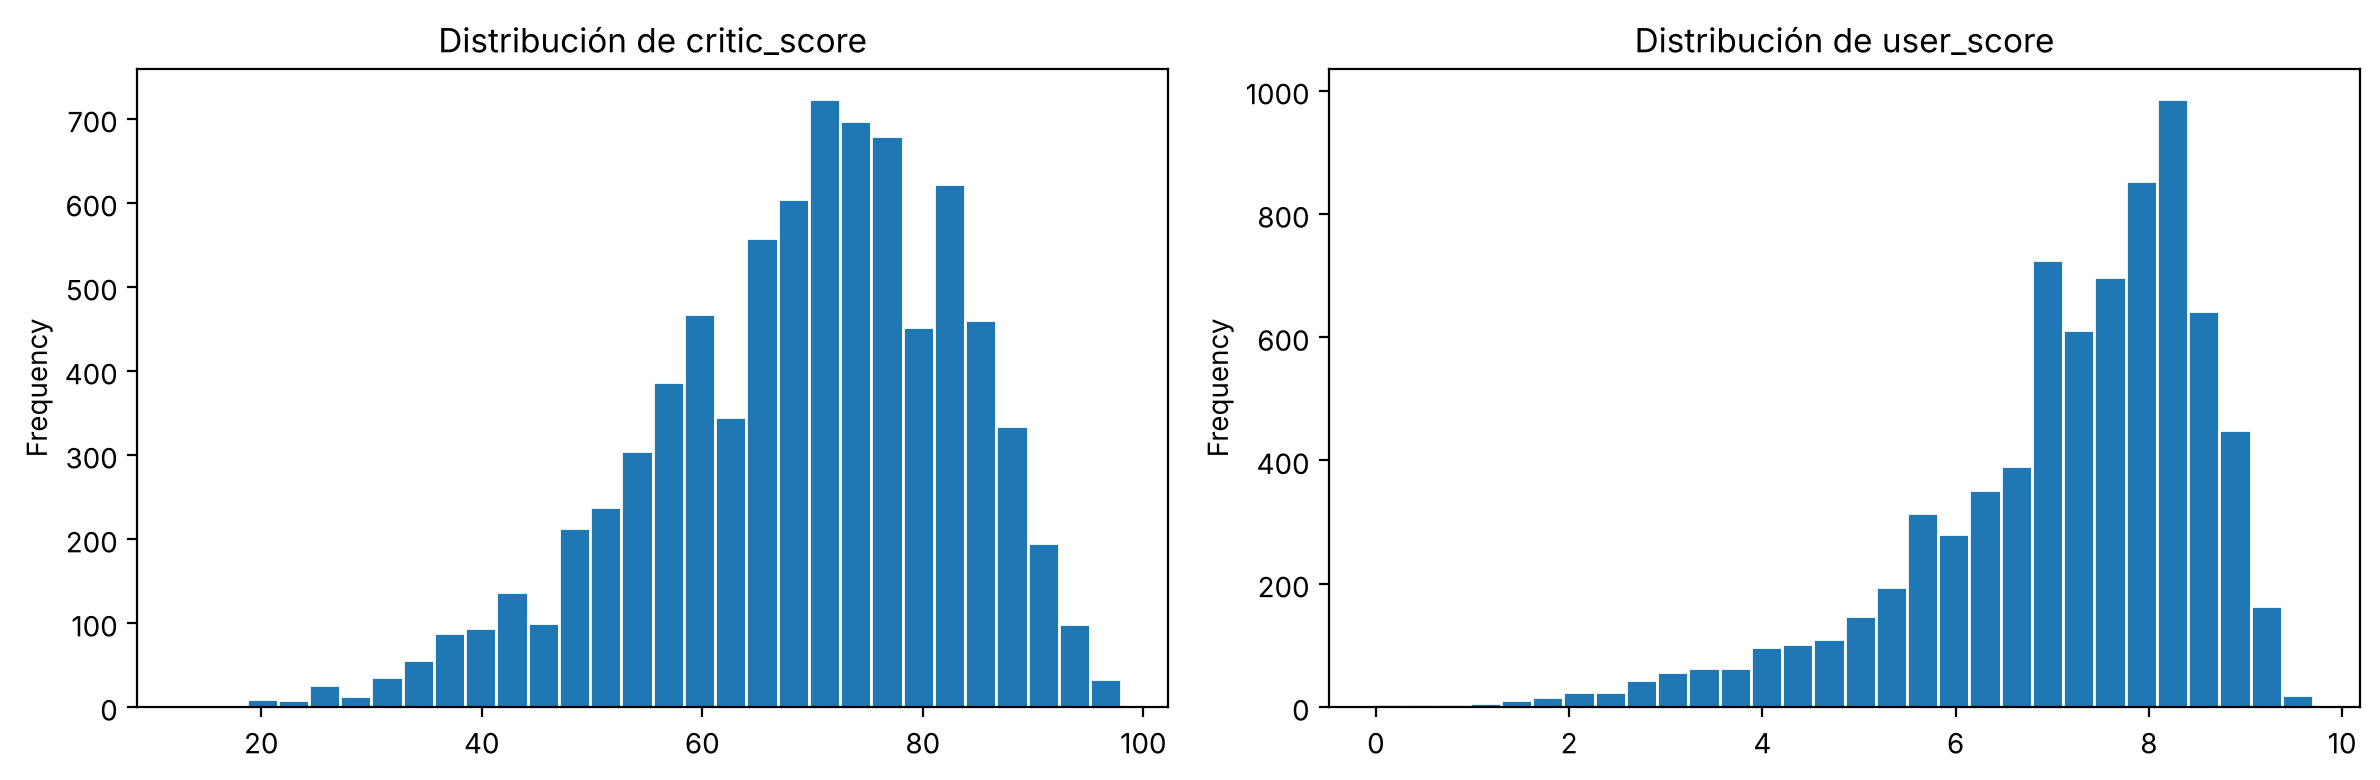

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df['critic_score'].plot(kind='hist', bins=30, ax=axes[0],
                        title='Distribución de critic_score', edgecolor='white')
df['user_score'].plot(kind='hist', bins=30, ax=axes[1],
                      title='Distribución de user_score', edgecolor='white')
plt.tight_layout()
plt.show()

In [17]:
# Porcentaje de juegos sin calificación de críticos por año
df.groupby('year_of_release')['critic_score'].apply(
    lambda s: s.isna().mean() * 100).loc[1994:].round(1)

year_of_release
1994     99.2
1995    100.0
1996     97.0
1997     94.1
1998     92.6
1999     88.5
2000     59.1
2001     32.4
2002     24.4
2003     24.5
2004     26.4
2005     30.2
2006     38.4
2007     42.2
2008     49.9
2009     54.3
2010     60.2
2011     56.0
2012     50.9
2013     49.8
2014     55.1
2015     62.9
2016     53.8
Name: critic_score, dtype: float64

Ambas distribuciones tienen **asimetría negativa**. Si hubiera que completar los valores ausentes la mejor medida a tomar sería la mediana. Aun así, tomé la decisión de dejar los valores ausentes como `NaN`, por estas razones:

- Alrededor de la mitad de los datos faltan por completarse, lo que pone en riesgo mi análisis, ya que, posiblemente muchos juegos llegasen a tener una puntuación alta.
- Qu hayan ausentes en esta columna no es un valor aleatorio. Le pasa a los juegos antiguos (antes de 1996 casi ninguno tiene reseña), a los títulos con pocas ventas y a los lanzamientos recientes (últimos años de la data) posiblemente aún no se hayan calificado.


### 2.6 `rating` (clasificación ESRB): valores ausentes


In [18]:
df['rating'].value_counts(dropna=False)

rating
NaN     6676
E       3920
T       2905
M       1536
E10+    1393
EC         8
K-A        3
AO         1
RP         1
Name: count, dtype: int64

In [19]:
# Concentración de juegos por calificación (ventas por región)
pd.DataFrame({
    'con rating': df[df['rating'].notna()][['na_sales', 'eu_sales', 'jp_sales']].sum(),
    'sin rating': df[df['rating'].isna()][['na_sales', 'eu_sales', 'jp_sales']].sum()
}).round(2)

,con rating,sin rating
na_sales,3115.58,1225.84
eu_sales,1790.02,609.65
jp_sales,453.90,836.74


En este atributo (es un rating: calificador de juegos), en este caso conviene conservar los **`NaN`** y como es un tipo de dato **`str`** se pasan al valor _unknown_, en este caso no podemos inferir la calificación, pero si conviene, mantener estos datos para próximamente analizarlos.

Además, investigando sobre las calificaciones me encuentro con que:

- **`K-A`** (_Kids to Adults_) es el nombre que tenía **`E`** antes, por lo que decidí unificarlos.
- **`RP`** (_Rating Pending_) significa que la clasificación todavía no se ha asignado, equivale a _unknown_.


In [20]:
df['rating'] = df['rating'].replace(
    {'K-A': 'E', 'RP': 'unknown'}).fillna('unknown')
df['rating'].value_counts()

rating
unknown    6677
E          3923
T          2905
M          1536
E10+       1393
EC            8
AO            1
Name: count, dtype: int64

### 2.7 Ventas totales


In [21]:
df['total_sales'] = df[['na_sales', 'eu_sales',
                        'jp_sales', 'other_sales']].sum(axis=1)
df[['name', 'platform', 'na_sales', 'eu_sales',
    'jp_sales', 'other_sales', 'total_sales']].head()

,name,platform,na_sales,eu_sales,jp_sales,other_sales,total_sales
0,Wii Sports,Wii,41.36,28.96,3.77,8.45,82.54
1,Super Mario Bros.,NES,29.08,3.58,6.81,0.77,40.24
2,Mario Kart Wii,Wii,15.68,12.76,3.79,3.29,35.52
3,Wii Sports Resort,Wii,15.61,10.93,3.28,2.95,32.77
4,Pokemon Red/Pokemon Blue,GB,11.27,8.89,10.22,1.00,31.38


### 2.8 Verificación final


In [22]:
df.info()
df.isna().sum()

<class 'pandas.DataFrame'>
Index: 16443 entries, 0 to 16711
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16443 non-null  str    
 1   platform         16443 non-null  str    
 2   year_of_release  16443 non-null  Int64  
 3   genre            16443 non-null  str    
 4   na_sales         16443 non-null  float64
 5   eu_sales         16443 non-null  float64
 6   jp_sales         16443 non-null  float64
 7   other_sales      16443 non-null  float64
 8   critic_score     7982 non-null   float64
 9   user_score       7462 non-null   float64
 10  rating           16443 non-null  str    
 11  total_sales      16443 non-null  float64
dtypes: Int64(1), float64(7), str(4)
memory usage: 1.6 MB


name                  0
platform              0
year_of_release       0
genre                 0
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8461
user_score         8981
rating                0
total_sales           0
dtype: int64

## Paso 3. Análisis exploratorio


### 3.1 Lanzamientos por año

**Objetivo:** ver cuántos juegos salieron cada año y si los datos de cada período son significativos.


In [23]:
# Conteo de juegos por año
juegos_por_anio = df['year_of_release'].value_counts().sort_index()
juegos_por_anio

year_of_release
1980       9
1981      46
1982      36
1983      17
1984      14
1985      14
1986      21
1987      16
1988      15
1989      17
1990      16
1991      41
1992      43
1993      60
1994     121
1995     219
1996     263
1997     289
1998     379
1999     338
2000     350
2001     482
2002     829
2003     775
2004     762
2005     939
2006    1006
2007    1197
2008    1427
2009    1426
2010    1255
2011    1136
2012     652
2013     544
2014     581
2015     606
2016     502
Name: count, dtype: Int64

- Los juegos que salen a principios del dataset en este caso el año 1980, suelen ser muy pocos hasta el año 1994 donde en este año de empiezan hacer significativa la cantidad de juegos que salen a partir de ese año


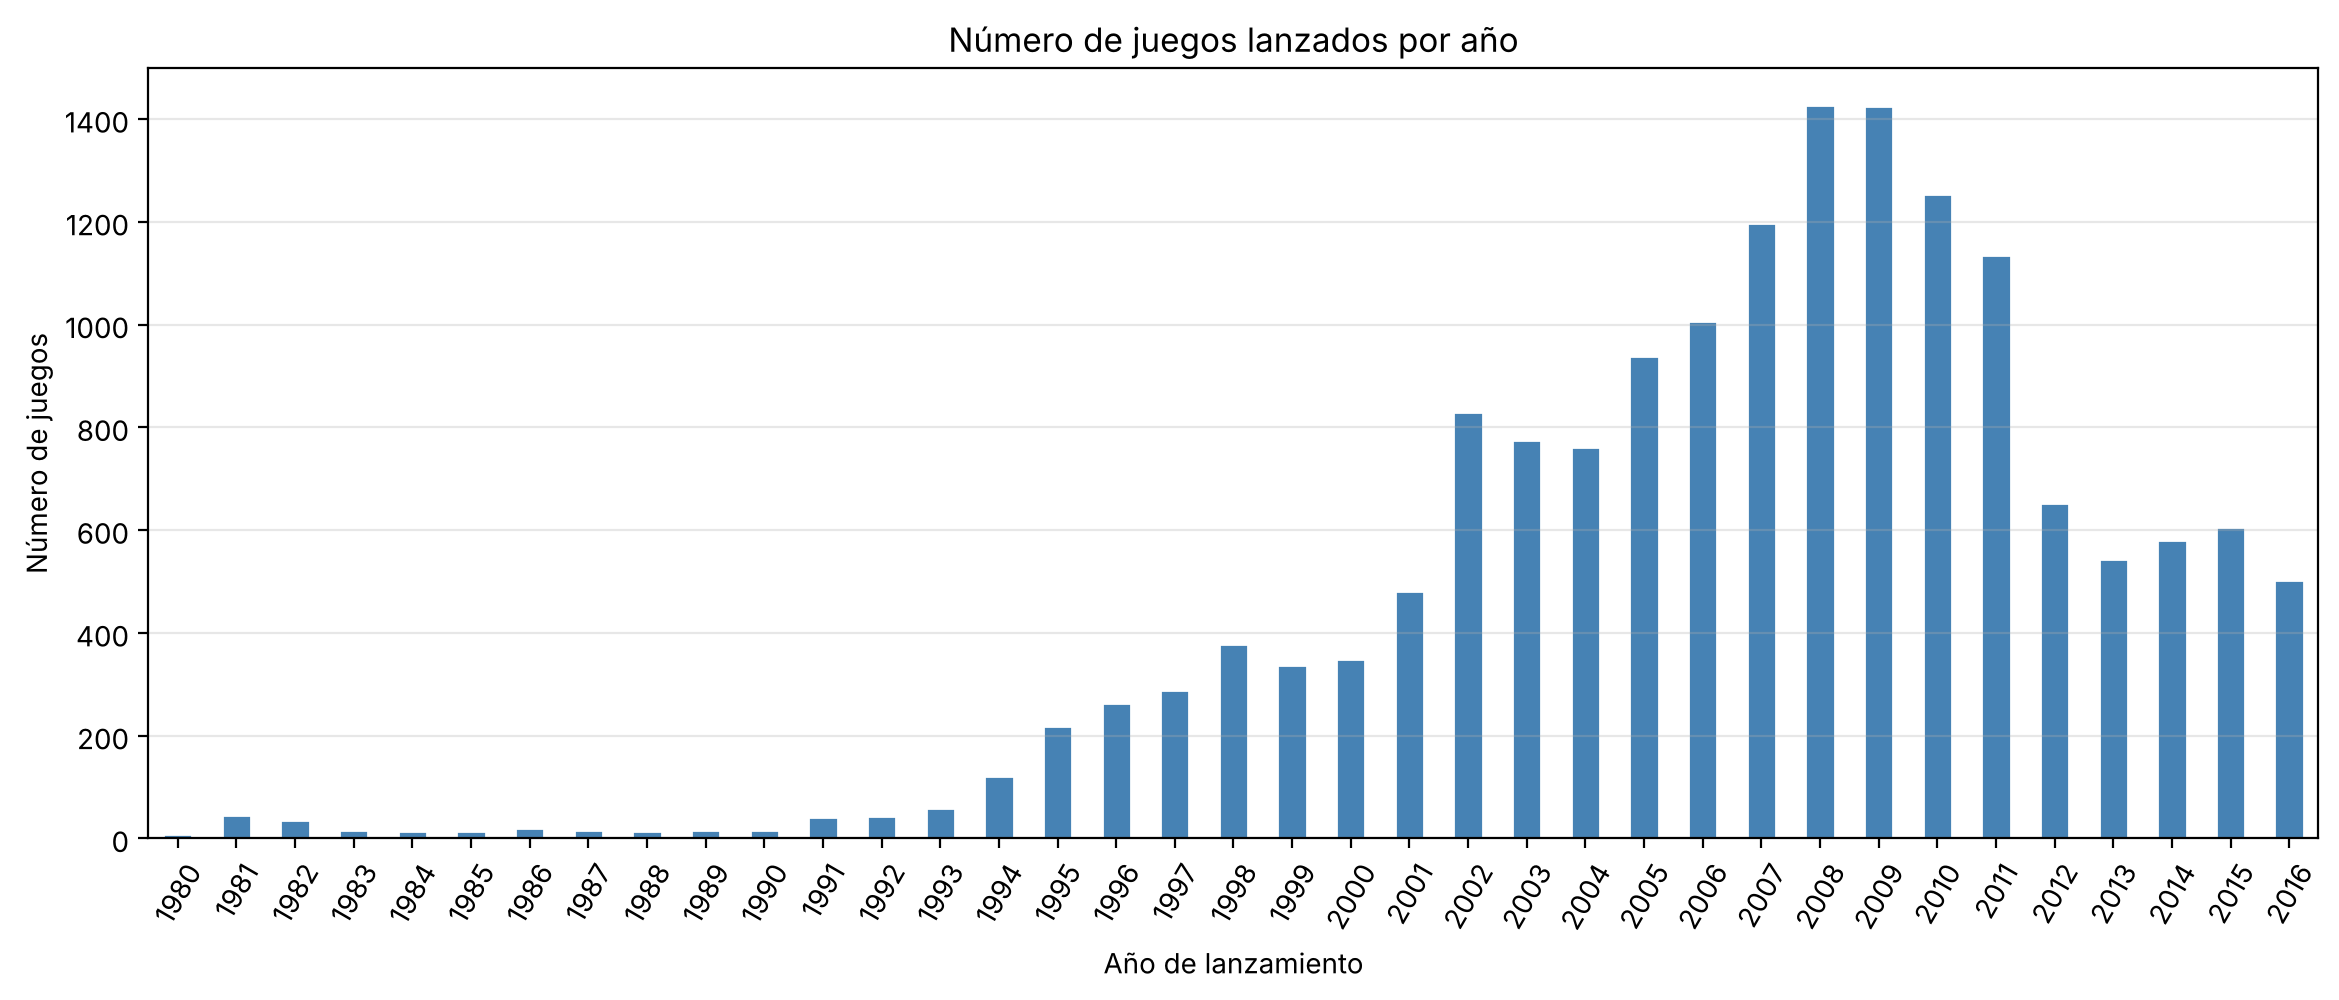

In [24]:
# Gráfico de barras de lanzamientos por año
juegos_por_anio.plot(kind='bar', figsize=(
    14, 5), color='steelblue', edgecolor='white')
plt.title('Número de juegos lanzados por año')
plt.xlabel('Año de lanzamiento')
plt.ylabel('Número de juegos')
plt.xticks(rotation=60)
plt.grid(axis='y', alpha=0.3)
plt.show()

- El pico está comprendido entre 2006-2011, aquí en estos años es donde la mayor cantidad de vieojuegos empezaron a lanzarce.
- El rango observado entre 1980 a 1990 no creo que sería significativa para planificar el 2017


### 3.2 Ventas por plataforma y ciclo de vida

**Objetivo:** identificar las plataformas con mayores ventas y entender cuánto tiempo "vive" una plataforma.


#### a) Ventas totales por plataforma


In [25]:
# Ventas totales por plataforma
ventas_plataforma = df.groupby(
    'platform')['total_sales'].sum().sort_values(ascending=False)
ventas_plataforma.head(10)

platform
PS2     1233.56
X360     961.24
PS3      931.33
Wii      891.18
DS       802.78
PS       727.58
PS4      314.14
GBA      312.88
PSP      289.53
3DS      257.81
Name: total_sales, dtype: float64

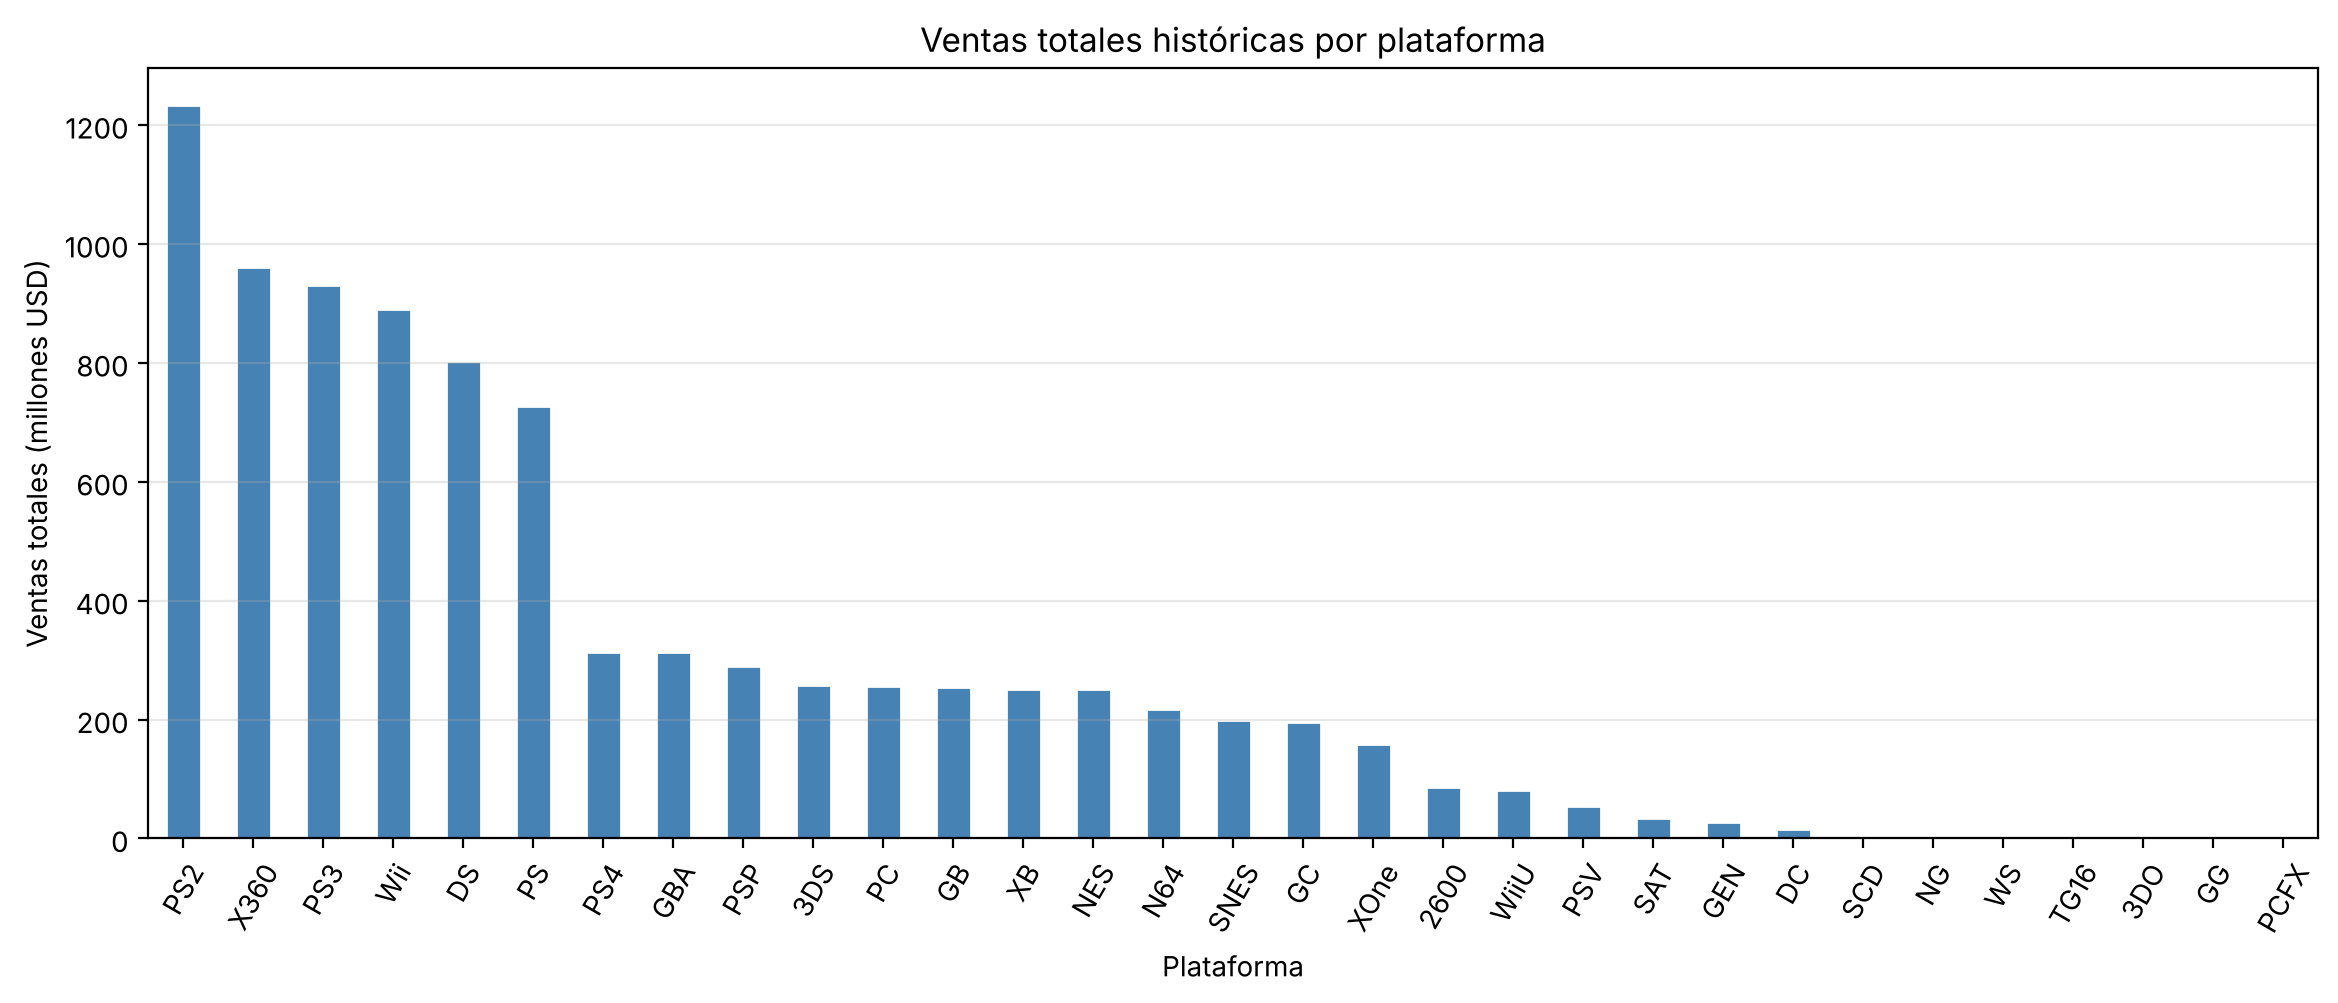

In [26]:
# Gráfico de barras de ventas por plataforma
ventas_plataforma.plot(kind='bar', figsize=(
    14, 5), color='steelblue', edgecolor='white')
plt.title('Ventas totales históricas por plataforma')
plt.xlabel('Plataforma')
plt.ylabel('Ventas totales (millones USD)')
plt.xticks(rotation=60)
plt.grid(axis='y', alpha=0.3)
plt.show()

#### b) Plataformas top


In [27]:
# Las 6 plataformas con mayores ventas históricas
top_plataformas = ventas_plataforma.head(6).index
top_plataformas

Index(['PS2', 'X360', 'PS3', 'Wii', 'DS', 'PS'], dtype='str', name='platform')

#### c) Distribución de ventas por año de las plataformas top


In [28]:
# Ventas anuales de las plataformas top: años en filas, plataformas en columnas
ventas_anuales_top = df[df['platform'].isin(top_plataformas)].pivot_table(
    index='year_of_release',
    columns='platform',
    values='total_sales',
    aggfunc='sum'
)
ventas_anuales_top

platform,DS,PS,PS2,PS3,Wii,X360
year_of_release,,,,,,
1985,0.02,NaN,NaN,NaN,NaN,NaN
1994,NaN,6.03,NaN,NaN,NaN,NaN
1995,NaN,35.96,NaN,NaN,NaN,NaN
1996,NaN,94.70,NaN,NaN,NaN,NaN
1997,NaN,136.17,NaN,NaN,NaN,NaN
1998,NaN,169.49,NaN,NaN,NaN,NaN
1999,NaN,144.53,NaN,NaN,NaN,NaN
2000,NaN,96.37,39.17,NaN,NaN,NaN
2001,NaN,35.59,166.43,NaN,NaN,NaN


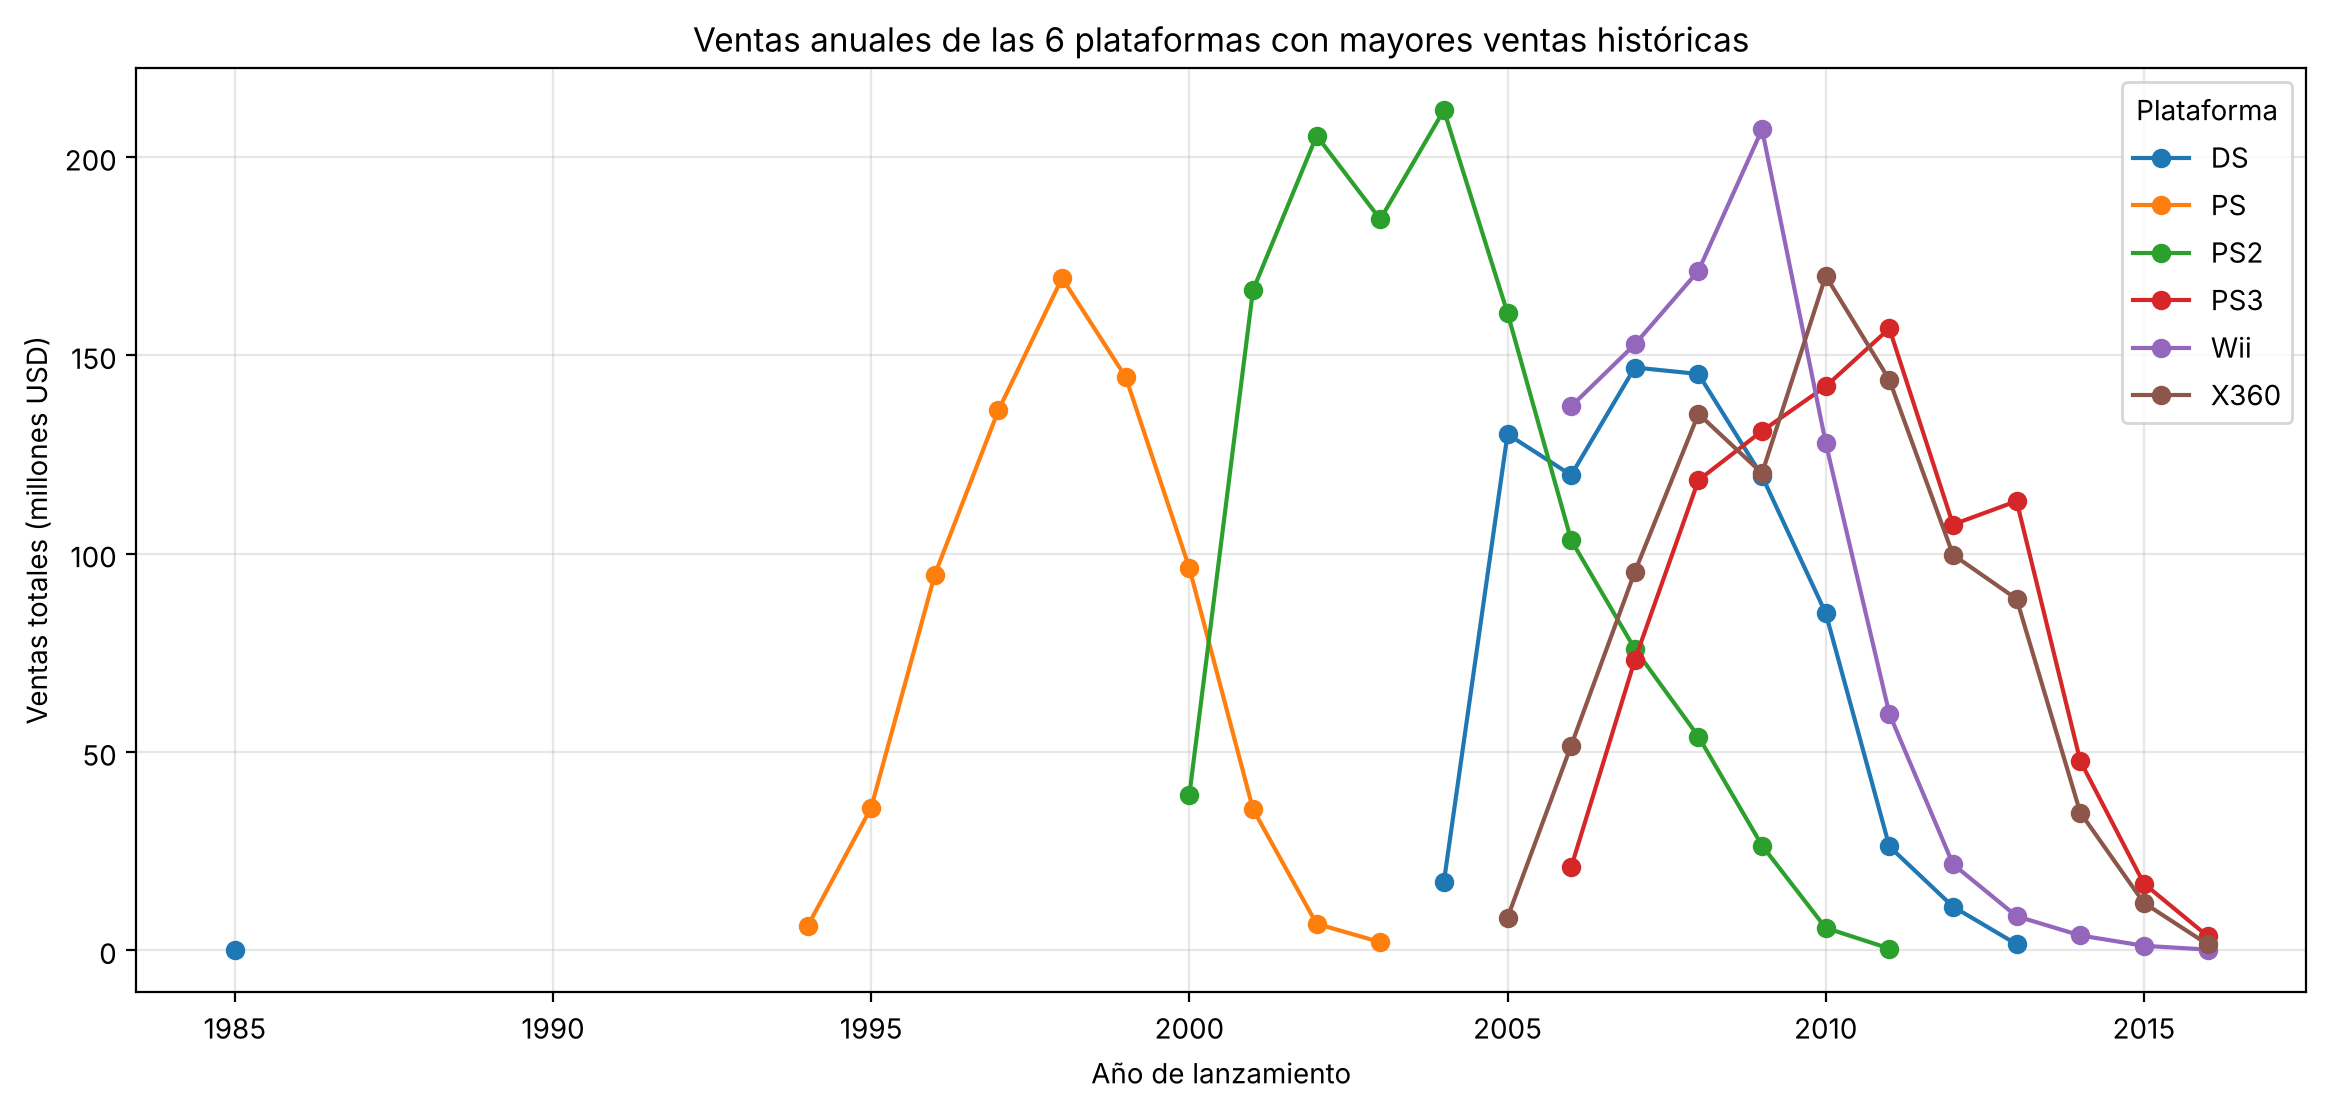

In [29]:
# Gráfico de líneas: ventas anuales por plataforma top
ventas_anuales_top.plot(figsize=(14, 6), marker='o')
plt.title('Ventas anuales de las 6 plataformas con mayores ventas históricas')
plt.xlabel('Año de lanzamiento')
plt.ylabel('Ventas totales (millones USD)')
plt.legend(title='Plataforma')
plt.grid(alpha=0.3)
plt.show()

#### d) Ciclo de vida de las plataformas


In [30]:
# Anomalía: la Nintendo DS salió en 2004, pero hay un registro de DS en 1985 (error de captura)
anomalias = df[(df['platform'] == 'DS') & (df['year_of_release'] < 2004)]

# Primer y último año con ventas de cada plataforma (sin la anomalía)
ciclo_vida = (
    df.drop(anomalias.index)
    .groupby('platform')['year_of_release']
    .agg(
        nace='min',
        muere='max')
)

ciclo_vida['anios_de_vida'] = ciclo_vida['muere'] - ciclo_vida['nace']
ciclo_vida['ventas_totales'] = ventas_plataforma
ciclo_vida.sort_values('nace')

,nace,muere,anios_de_vida,ventas_totales
platform,,,,
2600,1980,1989,9,86.48
NES,1983,1994,11,251.05
PC,1985,2016,31,255.76
GB,1988,2001,13,254.43
GEN,1990,1994,4,28.35
SNES,1990,1999,9,200.04
GG,1992,1992,0,0.04
NG,1993,1996,3,1.44
SCD,1993,1994,1,1.86


In [31]:
# Mediana de años de vida
terminadas = ciclo_vida[ciclo_vida['muere'] < 2016]

print('Mediana de vida (todas las plataformas):  ',
      ciclo_vida['anios_de_vida'].median(), 'años')
print('Mediana de vida (plataformas terminadas): ',
      terminadas['anios_de_vida'].median(), 'años')

# Años que tarda cada plataforma top en llegar a su pico de ventas
pico = pd.DataFrame({
    'año_lanzamiento': ciclo_vida.loc[top_plataformas, 'nace'],
    'año_pico': ventas_anuales_top.idxmax()
})

pico['años_hasta_pico'] = pico['año_pico'] - pico['año_lanzamiento']
pico

Mediana de vida (todas las plataformas):   6.0 años
Mediana de vida (plataformas terminadas):  6.5 años


,año_lanzamiento,año_pico,años_hasta_pico
platform,,,
DS,2004,2007,3
PS,1994,1998,4
PS2,2000,2004,4
PS3,2006,2011,5
Wii,2006,2009,3
X360,2005,2010,5


In [32]:
# Plataformas que solían ser populares (ventas históricas > 100 M) pero ya no tienen ventas en 2016
terminadas[terminadas['ventas_totales'] > 100].sort_values(
    'ventas_totales', ascending=False)

,nace,muere,anios_de_vida,ventas_totales
platform,,,,
PS2,2000,2011,11,1233.56
DS,2004,2013,9,802.78
PS,1994,2003,9,727.58
GBA,2000,2007,7,312.88
PSP,2004,2015,11,289.53
GB,1988,2001,13,254.43
XB,2000,2008,8,251.57
NES,1983,1994,11,251.05
N64,1996,2002,6,218.01


- Las plataformas líderes históricas son **PS2, X360, PS3, Wii, DS y PS**.
- Una plataforma vive en mediana unos **6-7 años** y llega a su pico de ventas en **3-5 años**.
- Aparece una nueva generación aproximadamente **cada 6 años** (PS 1994 → PS2 2000 → PS3 2006 → PS4 2013), y la anterior desaparece poco después.
- Varias plataformas que fueron muy populares ya no tienen ventas: **PS2, DS, PS, GBA, PSP, XB, GB, NES**, entre otras.
- Se detectó un registro de DS en 1985 (la DS salió en 2004). Es un error de captura y se excluyó del cálculo del ciclo de vida.


### 3.3 Período relevante para el análisis

**Objetivo:** decidir con qué años trabajar para construir un modelo útil para 2017.


In [33]:
# Periodo relevante

df_actual = df[df['year_of_release'] >= 2013].copy()
print('Registros en el período relevante:', len(df_actual))
print('\nPlataformas presentes:', sorted(df_actual['platform'].unique()))

Registros en el período relevante: 2233

Plataformas presentes: ['3DS', 'DS', 'PC', 'PS3', 'PS4', 'PSP', 'PSV', 'Wii', 'WiiU', 'X360', 'XOne']


- Los periodos que elegí son periodos para estimar la tendencia de plataformas que salieron a partir de la última generación, es decir, no tengo en cuenta plataformas que ya se les cumplió su ciclo de vida, en mi caso la última generación de plataformas sale a partir del año 2013.

- Los registros presentes actualmente para construir un modelo útil para el 2017 son $2233$ registros.


### 3.4 Plataformas líderes, en crecimiento y en declive

**Objetivo:** dentro del período relevante, identificar qué plataformas lideran, cuáles crecen y cuáles se reducen, y elegir las potencialmente rentables.


In [34]:
# Ventas totales por plataforma en el período relevante
ventas_plat_actual = df_actual.groupby(
    'platform')['total_sales'].sum().sort_values(ascending=False)
ventas_plat_actual

platform
PS4     314.14
PS3     181.43
XOne    159.32
3DS     143.25
X360    136.80
WiiU     64.63
PC       39.43
PSV      32.99
Wii      13.66
PSP       3.50
DS        1.54
Name: total_sales, dtype: float64

year_of_release,2013,2014,2015,2016
platform,,,,
PS4,25.99,100.00,118.90,69.25
XOne,18.96,54.07,60.14,26.15
3DS,56.57,43.76,27.78,15.14
PS3,113.25,47.76,16.82,3.60
WiiU,21.65,22.03,16.35,4.60
X360,88.58,34.74,11.96,1.52
PC,12.38,13.28,8.52,5.25
PSV,10.59,11.90,6.25,4.25
Wii,8.59,3.75,1.14,0.18


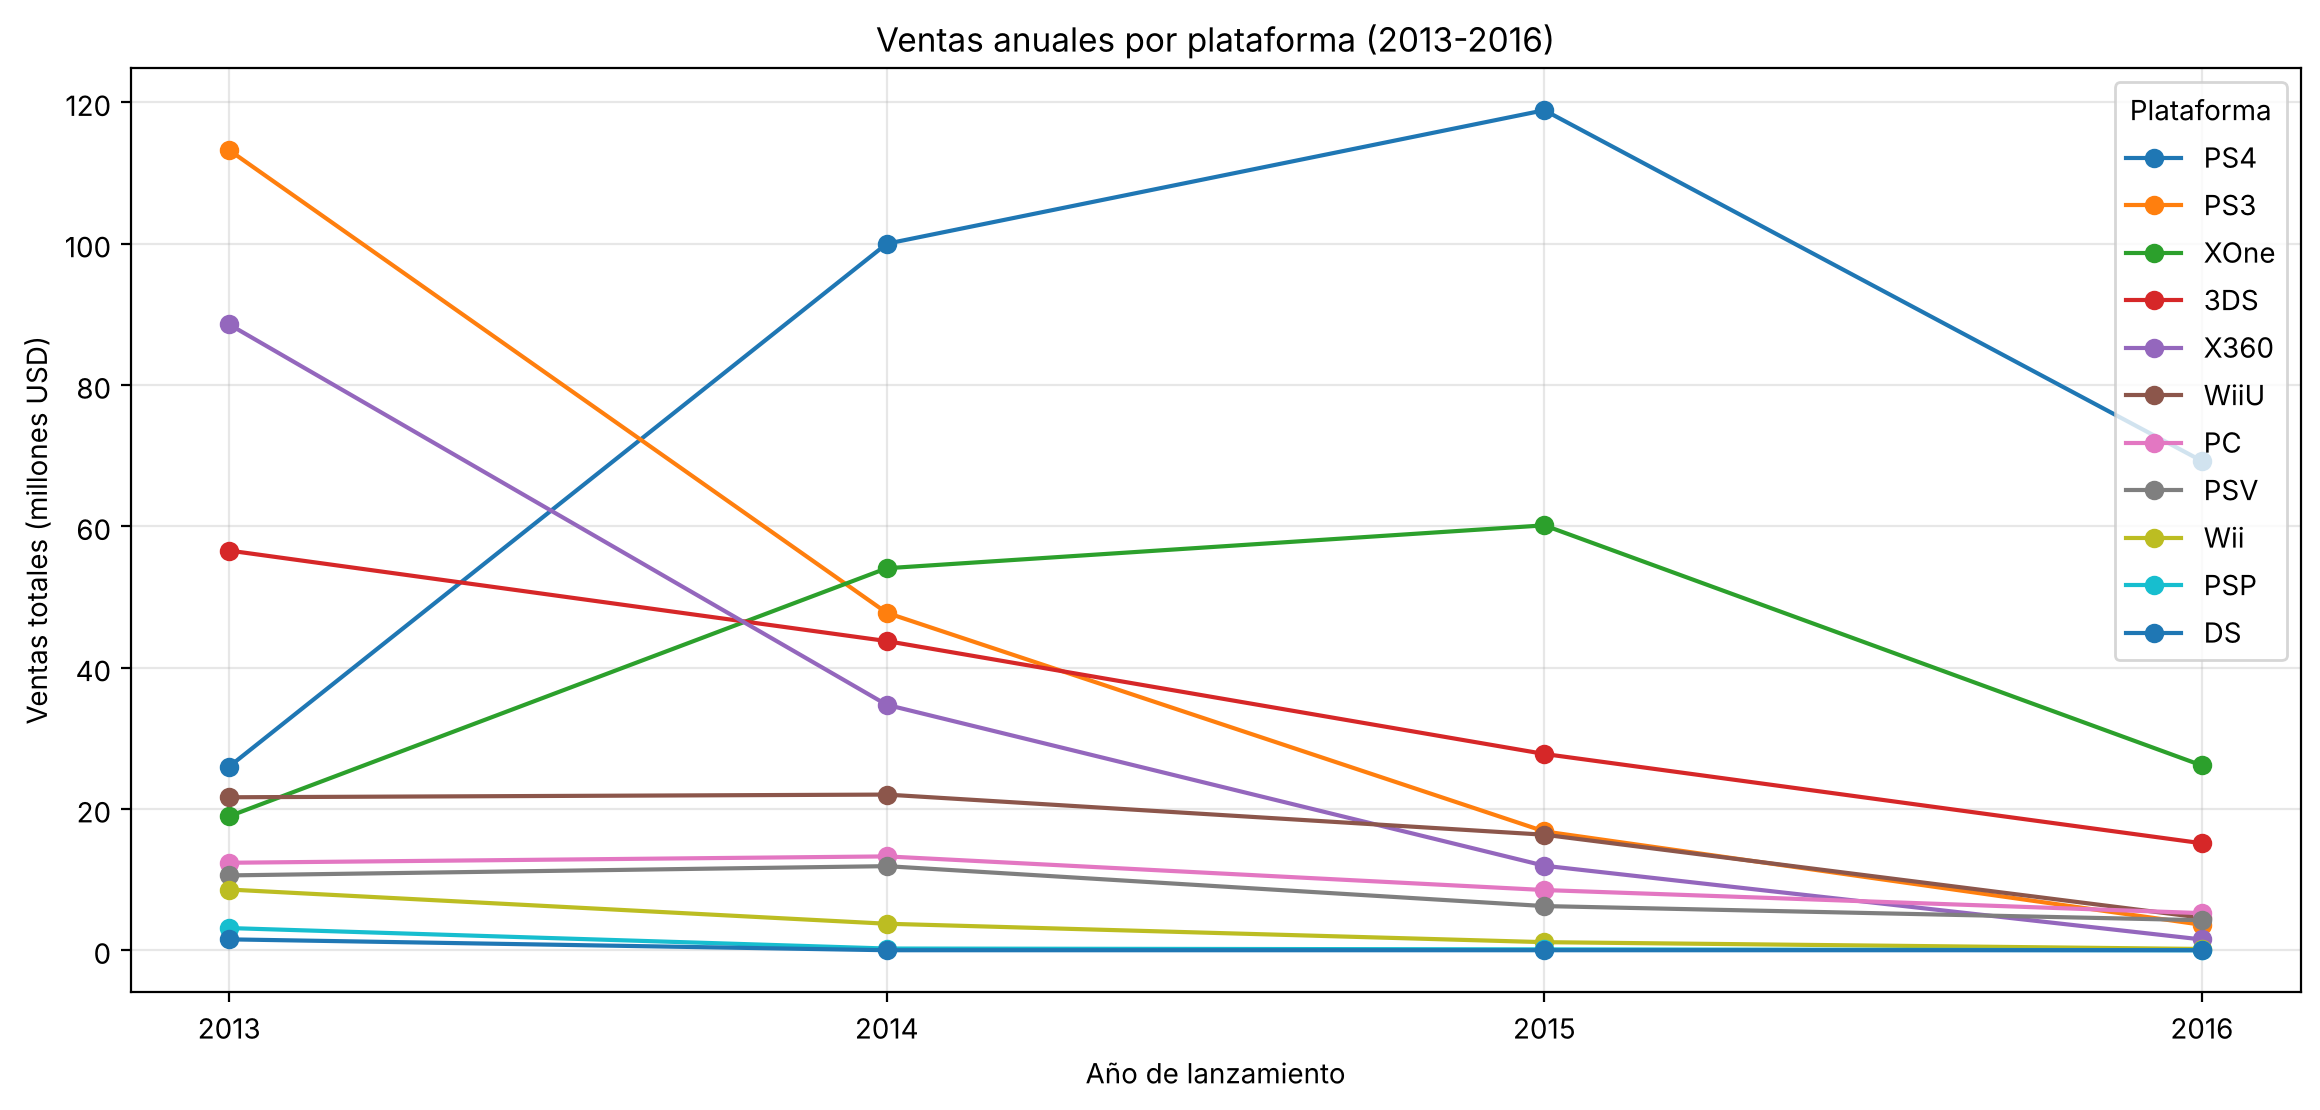

In [35]:
# Tabla año x plataforma y gráfico de tendencia
tendencia = df_actual.pivot_table(index='year_of_release', columns='platform',
                                  values='total_sales', aggfunc='sum').fillna(0)
display(tendencia.T.sort_values(2015, ascending=False))

tendencia[ventas_plat_actual.index].plot(figsize=(14, 6), marker='o')
plt.title('Ventas anuales por plataforma (2013-2016)')
plt.xlabel('Año de lanzamiento')
plt.ylabel('Ventas totales (millones USD)')
plt.xticks(tendencia.index)
plt.legend(title='Plataforma', loc='upper right')
plt.grid(alpha=0.3)
plt.show()

- Las plataformas líderes en 2013-2016 son **PS4 (314 M)**, PS3 (181 M), **XOne (159 M)** y 3DS (143 M).
- Solo **PS4 y XOne crecen**: aumentan sus ventas cada año hasta 2015. La caída de 2016 se explica al final del proyecto bien dice que los datos de ese año están incompletos.
- PS3, X360, Wii, PSP y DS están en **declive** porque su generación ya fue reemplazada. La 3DS y la WiiU también bajan año tras año.
- Las potencialmente rentables para 2017 son **PS4 y XOne** como apuesta principal. La **3DS** es relevante para Japón y el **PC** es un mercado pequeño pero estable.


### 3.5 Diagrama de caja de ventas globales por plataforma

**Objetivo:** comparar la distribución de ventas por juego entre plataformas.


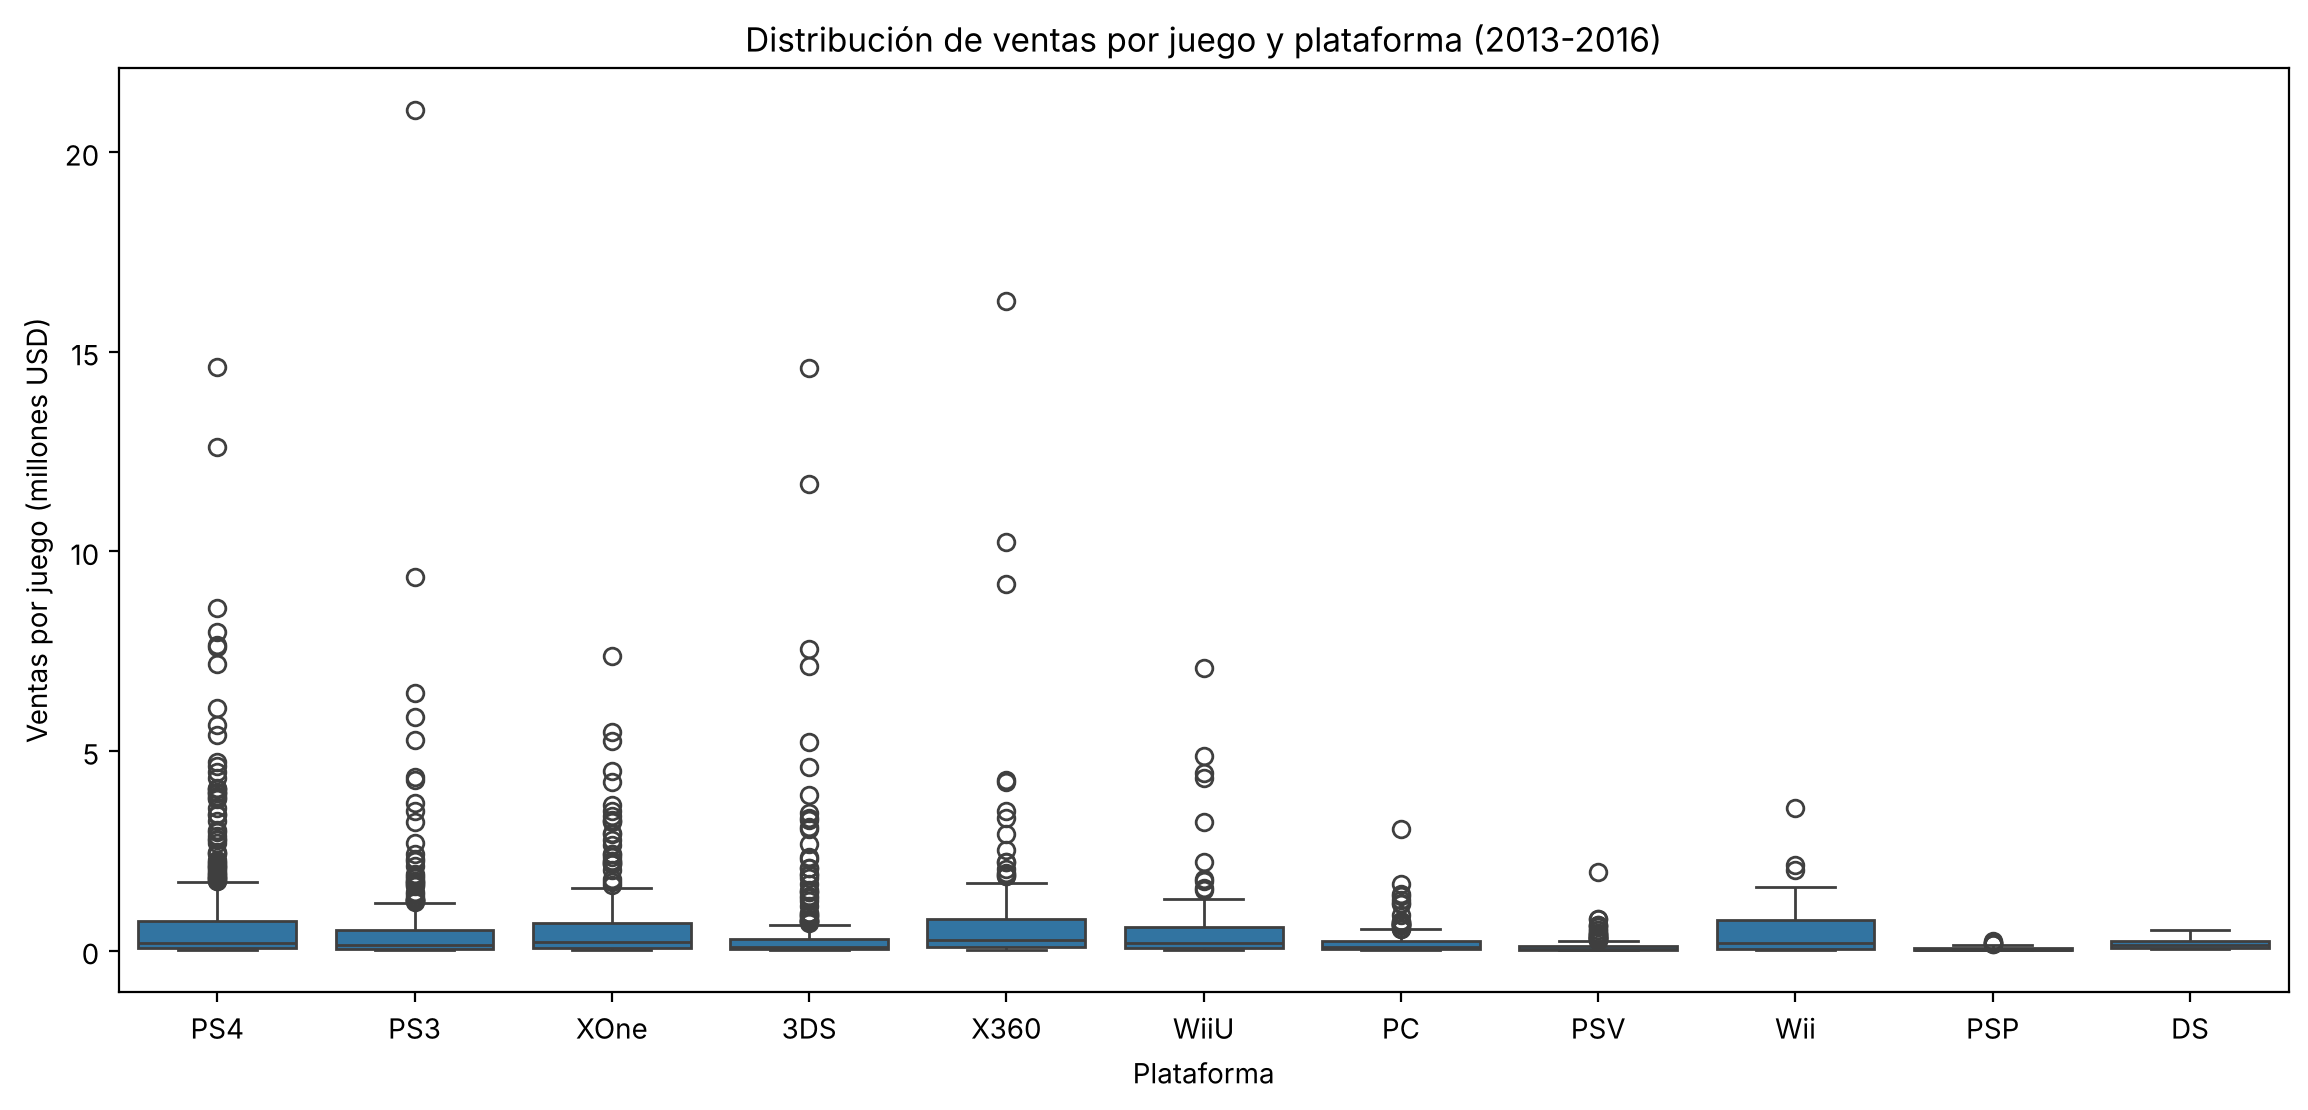

In [36]:
# Boxplot de ventas por juego, por plataforma (ordenadas por ventas totales)
plt.figure(figsize=(14, 6))
sns.boxplot(data=df_actual, x='platform', y='total_sales',
            order=ventas_plat_actual.index)
plt.title('Distribución de ventas por juego y plataforma (2013-2016)')
plt.xlabel('Plataforma')
plt.ylabel('Ventas por juego (millones USD)')
plt.show()

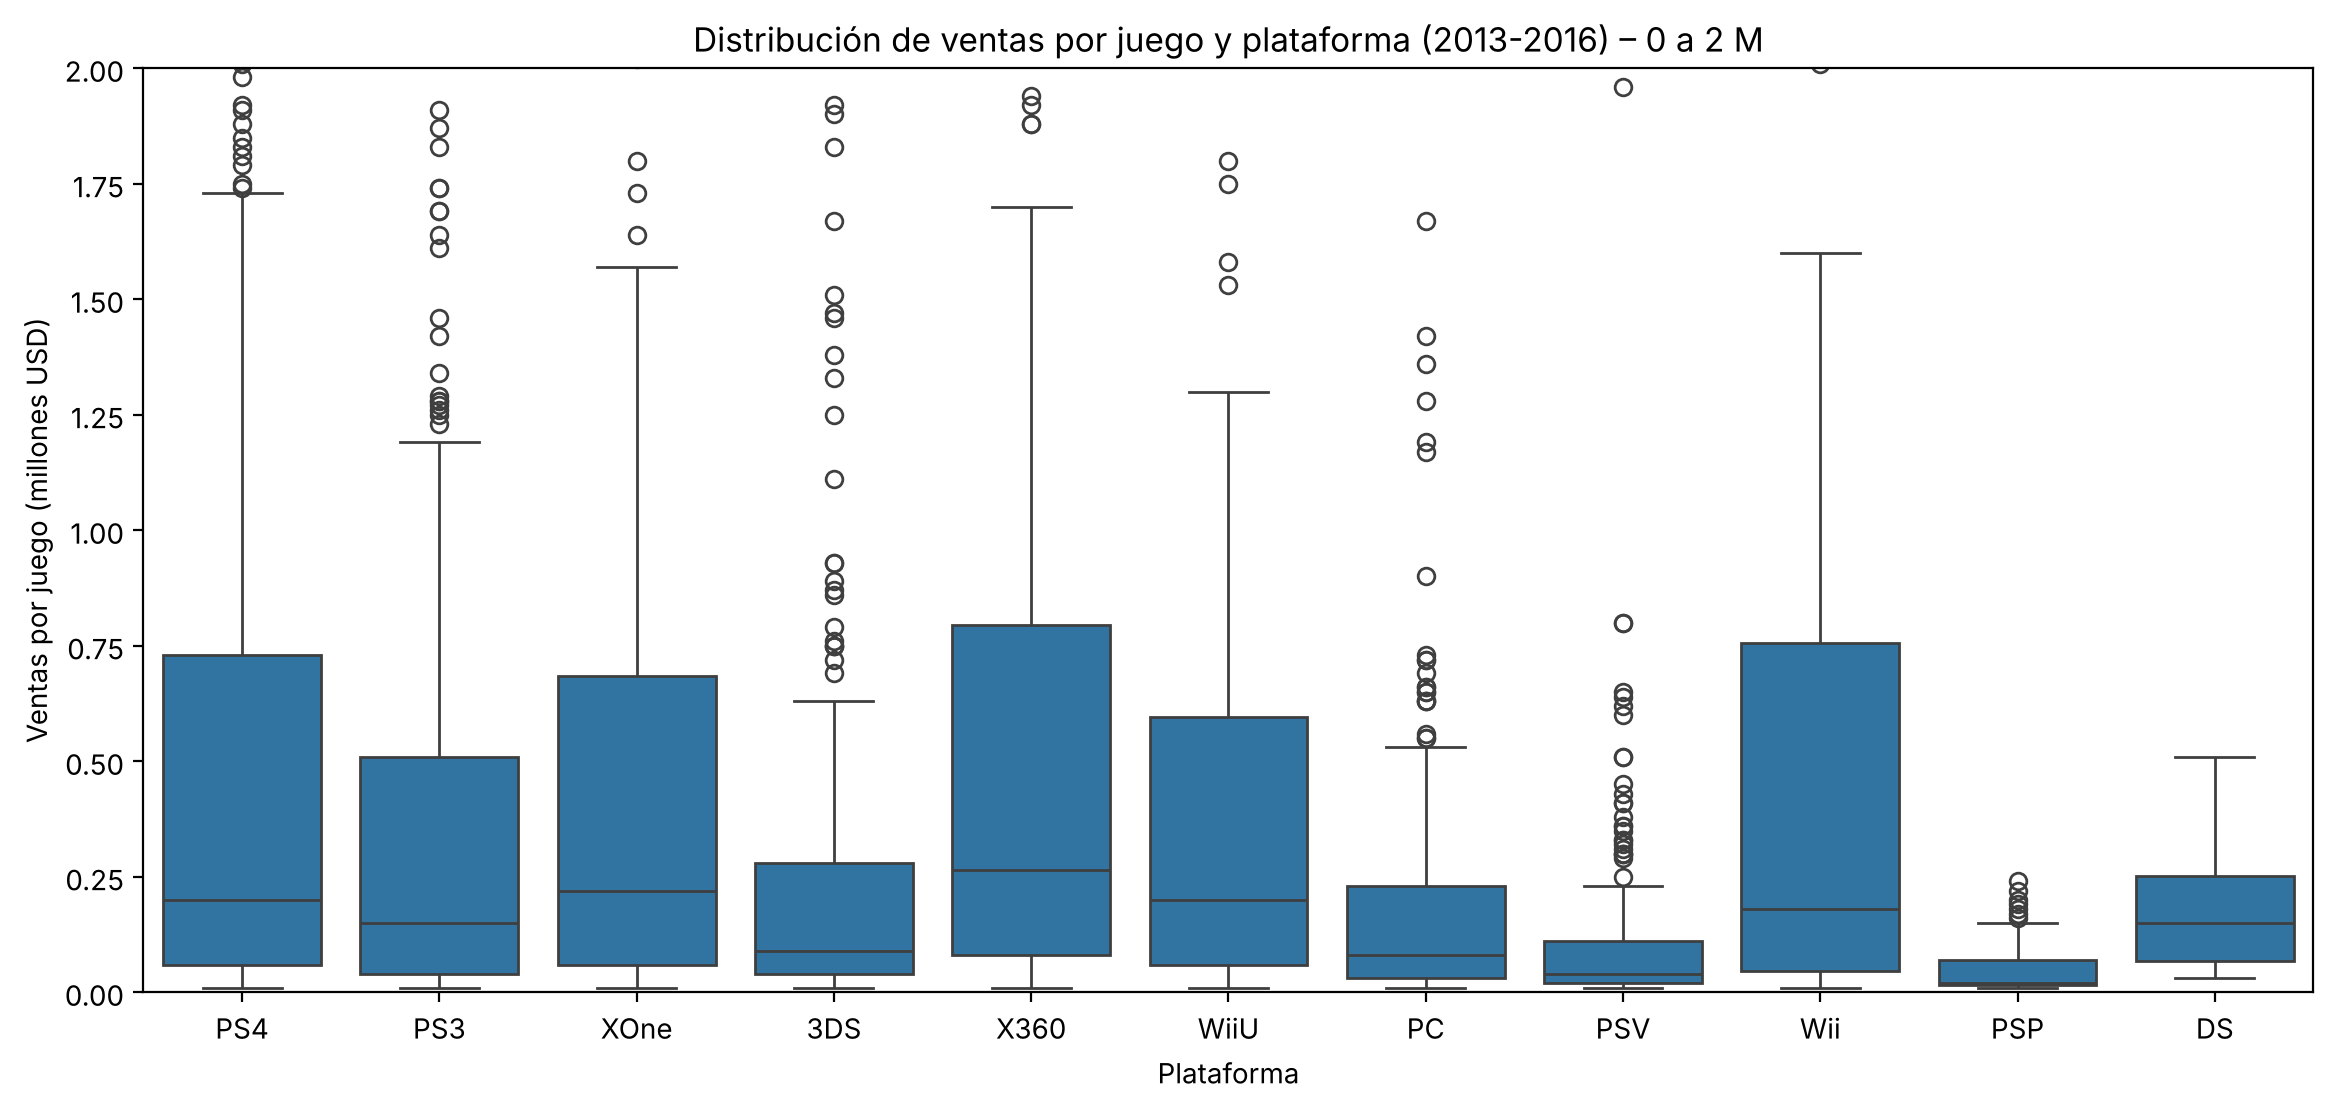

In [37]:
# Mismo boxplot con el eje Y limitado para ver las cajas
plt.figure(figsize=(14, 6))
sns.boxplot(data=df_actual, x='platform', y='total_sales',
            order=ventas_plat_actual.index)
plt.ylim(0, 2)
plt.title('Distribución de ventas por juego y plataforma (2013-2016) – 0 a 2 M')
plt.xlabel('Plataforma')
plt.ylabel('Ventas por juego (millones USD)')
plt.show()

In [38]:
# Número de juegos, media y mediana de ventas por juego
df_actual.groupby('platform')['total_sales'].agg(
    ['count', 'mean', 'median']).round(3).sort_values('median', ascending=False)

,count,mean,median
platform,,,
X360,186,0.735,0.265
XOne,247,0.645,0.220
PS4,392,0.801,0.200
WiiU,115,0.562,0.200
Wii,23,0.594,0.180
DS,8,0.192,0.150
PS3,345,0.526,0.150
3DS,303,0.473,0.090
PC,189,0.209,0.080


- Todas las plataformas tienen muchos **valores atípicos**: unos pocos _best-sellers_ venden mucho más que el resto.
- Por eso la **media es mucho mayor que la mediana** (PS4: 0,80 M de media frente a 0,20 M de mediana).
- Con lo anterior nos lleva a inferir que las ventas totales de una plataforma dependen sobre todo de sus éxitos (valores atípicos).
- Las medianas más altas son las de **X360, XOne, PS4 y WiiU** (aprox 0,2 M por juego). PSV y PSP venden muy poco por juego.
- Las diferencias entre plataformas sí son significativas. Un juego típico de consola de hogar vende varias veces más que uno de PC o de una consola portátil.


### 3.6 Efecto de las reseñas en las ventas (una plataforma popular)

**Objetivo:** ver si las calificaciones de críticos y usuarios se relacionan con las ventas.


In [39]:
# Plataforma elegida: PS4 (la de mayores ventas en el período relevante)
ps4 = df_actual[df_actual['platform'] == 'PS4']
print('Juegos de PS4:', len(ps4))
print('Con critic_score:', ps4['critic_score'].notna().sum())
print('Con user_score:  ', ps4['user_score'].notna().sum())

Juegos de PS4: 392
Con critic_score: 252
Con user_score:   257


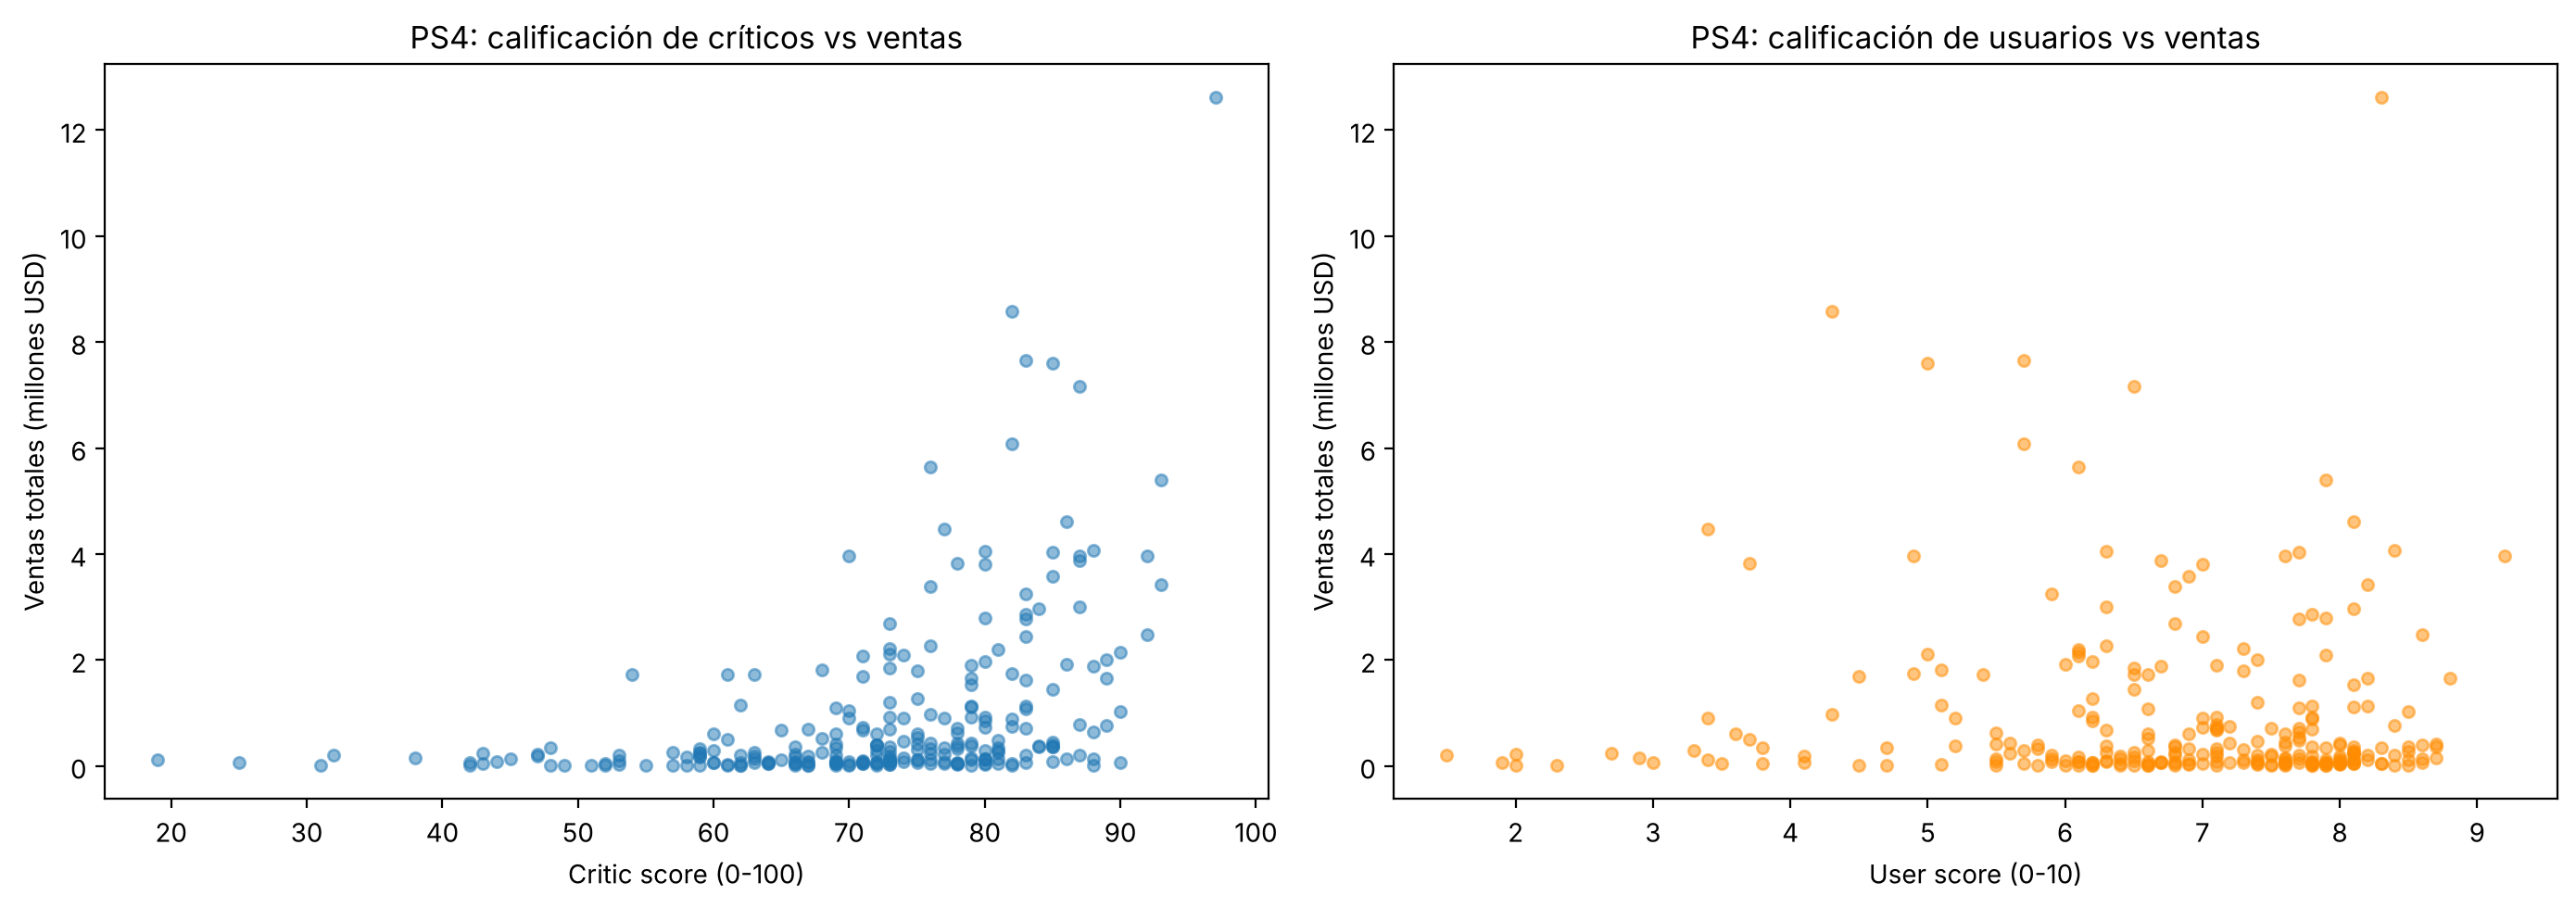

In [40]:
# Gráficos de dispersión: reseñas vs ventas en PS4
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ps4.plot(kind='scatter', x='critic_score',
         y='total_sales', alpha=0.5, ax=axes[0])
axes[0].set_title('PS4: calificación de críticos vs ventas')
axes[0].set_xlabel('Critic score (0-100)')
axes[0].set_ylabel('Ventas totales (millones USD)')

ps4.plot(kind='scatter', x='user_score', y='total_sales',
         alpha=0.5, color='darkorange', ax=axes[1])
axes[1].set_title('PS4: calificación de usuarios vs ventas')
axes[1].set_xlabel('User score (0-10)')
axes[1].set_ylabel('Ventas totales (millones USD)')

plt.tight_layout()
plt.show()

In [41]:
# Correlación de Pearson (pandas ignora los NaN automáticamente)
print(
    f"Correlación critic_score vs ventas: {ps4['critic_score'].corr(ps4['total_sales']):.2f}")
print(
    f"Correlación user_score vs ventas:   {ps4['user_score'].corr(ps4['total_sales']):.2f}")

Correlación critic_score vs ventas: 0.41
Correlación user_score vs ventas:   -0.03


- En PS4, la calificación de los **críticos** tiene una **correlación positiva moderada (0,41)** con las ventas. Los juegos mejor valorados tienden a vender más, aunque no siempre suele ser así.
- La calificación de los **usuarios no tiene relación con las ventas (−0,03)**.
- En el gráfico de dispersión se ve que los juegos con ventas altas casi siempre tienen una nota de críticos superior a 70, ahí está su _"relación directa"_.


### 3.7 Comparación con otras plataformas

**Objetivo:** comprobar si la conclusión anterior se mantiene en otras plataformas.


In [42]:
# Correlaciones por plataforma (solo plataformas con al menos 30 juegos con reseña)
resultados = []
for plataforma in ventas_plat_actual.index:
    datos = df_actual[df_actual['platform'] == plataforma]
    n_criticos = datos['critic_score'].notna().sum()
    n_usuarios = datos['user_score'].notna().sum()
    if max(n_criticos, n_usuarios) < 30:
        continue
    resultados.append({
        'platform': plataforma,
        'n_critic': n_criticos,
        'corr_critic': datos['critic_score'].corr(datos['total_sales']),
        'n_user': n_usuarios,
        'corr_user': datos['user_score'].corr(datos['total_sales'])
    })

correlaciones = pd.DataFrame(resultados).set_index('platform').round(3)
correlaciones

,n_critic,corr_critic,n_user,corr_user
platform,,,,
PS4,252,0.407,257,-0.032
PS3,121,0.334,186,0.002
XOne,169,0.417,182,-0.069
3DS,71,0.357,80,0.242
X360,81,0.350,143,-0.012
WiiU,70,0.376,80,0.419
PC,149,0.196,155,-0.094
PSV,77,0.255,99,0.001


In [43]:
# Mismos juegos en distintas plataformas: juegos de PS4 que también salieron en otras plataformas
multiplataforma = df_actual[df_actual['name'].isin(ps4['name'])]

comparacion = multiplataforma.pivot_table(index='name', columns='platform',
                                          values='total_sales', aggfunc='sum')

comparacion = comparacion[comparacion.notna().sum(axis=1) > 1]
print('Juegos de PS4 que también salieron en otras plataformas:', len(comparacion))

# Ventas medianas de esos mismos juegos en cada plataforma
plataformas_principales = ['PS4', 'XOne', 'PS3', 'X360', 'PC', 'WiiU']
comparacion[plataformas_principales].median(
).sort_values(ascending=False).round(3)

Juegos de PS4 que también salieron en otras plataformas: 316


platform
X360    0.425
PS4     0.265
PS3     0.250
WiiU    0.240
XOne    0.210
PC      0.100
dtype: float64

- El patrón se repite en casi todas las plataformas: la nota de los **críticos** tiene una correlación de 0,2 a 0,42 con las ventas y la de los **usuarios** se queda cerca de 0.
- Las excepciones son **WiiU (0,42)** y **3DS (0,24)**, donde la nota de los usuarios sí tiene cierta relación con las ventas.
- Si se comparan los mismos juegos en varias plataformas, **X360, PS4 y PS3** obtienen las mayores ventas medianas, mientras que en **PC** venden mucho menos.


### 3.8 Distribución por género

**Objetivo:** identificar los géneros más rentables.


In [44]:
# Conteo y ventas por género (período relevante)
generos = df_actual.groupby('genre')['total_sales'].agg(
    ['count', 'sum', 'mean', 'median']).round(3)
generos.sort_values('sum', ascending=False)

,count,sum,mean,median
genre,,,,
Action,766,321.87,0.420,0.110
Shooter,187,232.98,1.246,0.450
Sports,214,150.65,0.704,0.240
Role-Playing,292,145.89,0.500,0.125
Misc,155,62.82,0.405,0.100
Platform,74,42.63,0.576,0.225
Racing,85,39.89,0.469,0.120
Fighting,80,35.31,0.441,0.125
Adventure,245,23.64,0.096,0.030


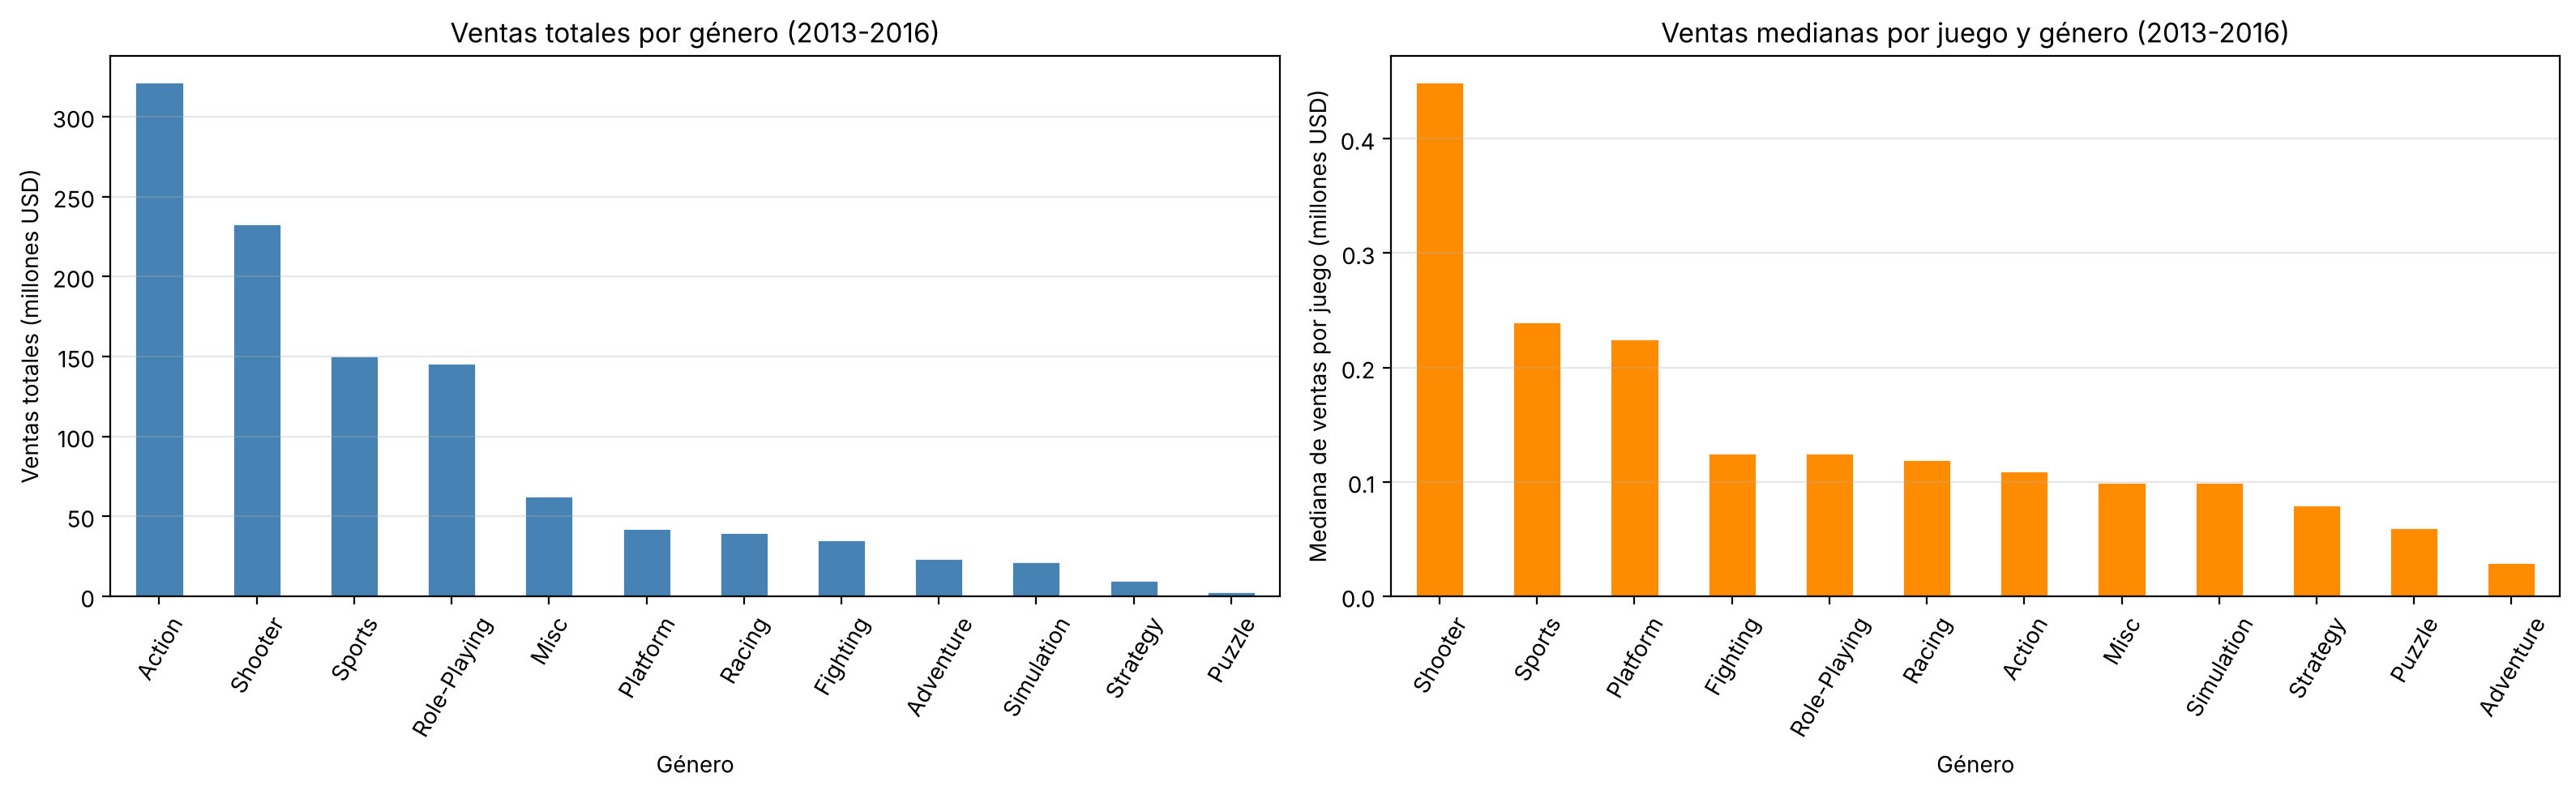

In [45]:
# Gráficos por género: ventas totales vs ventas medianas por juego
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

generos['sum'].sort_values(ascending=False).plot(
    kind='bar', ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('Ventas totales por género (2013-2016)')
axes[0].set_xlabel('Género')
axes[0].set_ylabel('Ventas totales (millones USD)')

generos['median'].sort_values(ascending=False).plot(
    kind='bar', ax=axes[1], color='darkorange', edgecolor='white')
axes[1].set_title('Ventas medianas por juego y género (2013-2016)')
axes[1].set_xlabel('Género')
axes[1].set_ylabel('Mediana de ventas por juego (millones USD)')

for ax in axes:
    ax.tick_params(axis='x', rotation=60)
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

- **Action** es el género con más ventas totales, pero también el que tiene más lanzamientos (766). Su mediana por juego es baja (0,11 M).
- **Shooter** es el género más **rentable por juego** (mediana 0,45 M), seguido de **Sports** (0,24 M) y **Platform** (0,23 M).
- **Adventure, Puzzle y Strategy** son los que menos venden, tanto en total como por juego.

Un género puede vender mucho en total solo por volumen de lanzamientos, pero, para medir la rentabilidad conviene mirar la venta **por juego** directamente.


## Paso 4. Perfil de usuario por región

Se trabaja con el período relevante, en este caso `df_actual` comprendido entre 2013-2016. Para cada región (NA, UE, JP) se calculan las cinco plataformas y los cinco géneros principales según su participación en las ventas, y las ventas por clasificación ESRB.


### 4.1 Cinco plataformas principales por región


In [46]:
regiones = ['na_sales', 'eu_sales', 'jp_sales']

for region in regiones:
    ventas = df_actual.groupby('platform')[
        region].sum().sort_values(ascending=False)
    participacion = (ventas / ventas.sum() * 100).round(1)
    print(f'--- {region} (participación en mercado %) ---')
    print(participacion.head(5), '\n')

--- na_sales (participación en mercado %) ---
platform
PS4     24.8
XOne    21.3
X360    18.7
PS3     14.5
3DS      8.7
Name: na_sales, dtype: float64 

--- eu_sales (participación en mercado %) ---
platform
PS4     36.0
PS3     17.3
XOne    13.2
X360    10.8
3DS      7.9
Name: eu_sales, dtype: float64 

--- jp_sales (participación en mercado %) ---
platform
3DS     48.2
PS3     16.6
PSV     13.2
PS4     11.3
WiiU     7.7
Name: jp_sales, dtype: float64 



- **NA:** el mercado está repartido entre PlayStation y Xbox (PS4 24.8 % y XOne 21.3 %). Xbox es fuerte por ser una marca estadounidense.
- **UE:** domina **PS4 (36 %)**, seguida de PS3. Xbox tiene menos peso que en la región NA.
- **JP:** el mercado es muy distinto: lideran las **consolas portátiles de Nintendo y Sony** (3DS 48.2 %, PSV 13.2 %) y Xbox no está ni en el top 5.


### 4.2 Cinco géneros principales por región


In [47]:
for region in regiones:
    ventas = df_actual.groupby(
        'genre')[region].sum().sort_values(ascending=False)
    participacion = (ventas / ventas.sum() * 100).round(1)
    print(f'--- {region} (participación de mercado %) ---')
    print(participacion.head(5), '\n')

--- na_sales (participación de mercado %) ---
genre
Action          28.8
Shooter         25.1
Sports          14.9
Role-Playing    10.6
Misc             6.3
Name: na_sales, dtype: float64 

--- eu_sales (participación de mercado %) ---
genre
Action          30.1
Shooter         22.4
Sports          15.4
Role-Playing     9.4
Racing           5.1
Name: eu_sales, dtype: float64 

--- jp_sales (participación de mercado %) ---
genre
Role-Playing    36.3
Action          28.8
Misc             6.5
Fighting         5.4
Shooter          4.7
Name: jp_sales, dtype: float64 



- **NA y UE** tienen gustos casi iguales: Action, Shooter, Sports y Role-Playing ocupan los primeros puestos y casi que con la misma participación cada uno.
- **JP** prefiere claramente **Role-Playing (36 %)**, con Action en segundo lugar, Shooter casi no pesa 4.7%, lo que se relaciona con el favortismo hacie las consolas portátiles y juegos RPG.


### 4.3 Efecto de la clasificación ESRB por región


In [48]:
ventas_rating = df_actual.pivot_table(
    index='rating', values=regiones, aggfunc='sum')
ventas_rating

,eu_sales,jp_sales,na_sales
rating,,,
E,83.36,15.14,79.05
E10+,42.69,5.89,54.24
M,145.32,14.11,165.21
T,41.95,20.59,49.79
unknown,78.91,85.05,89.42


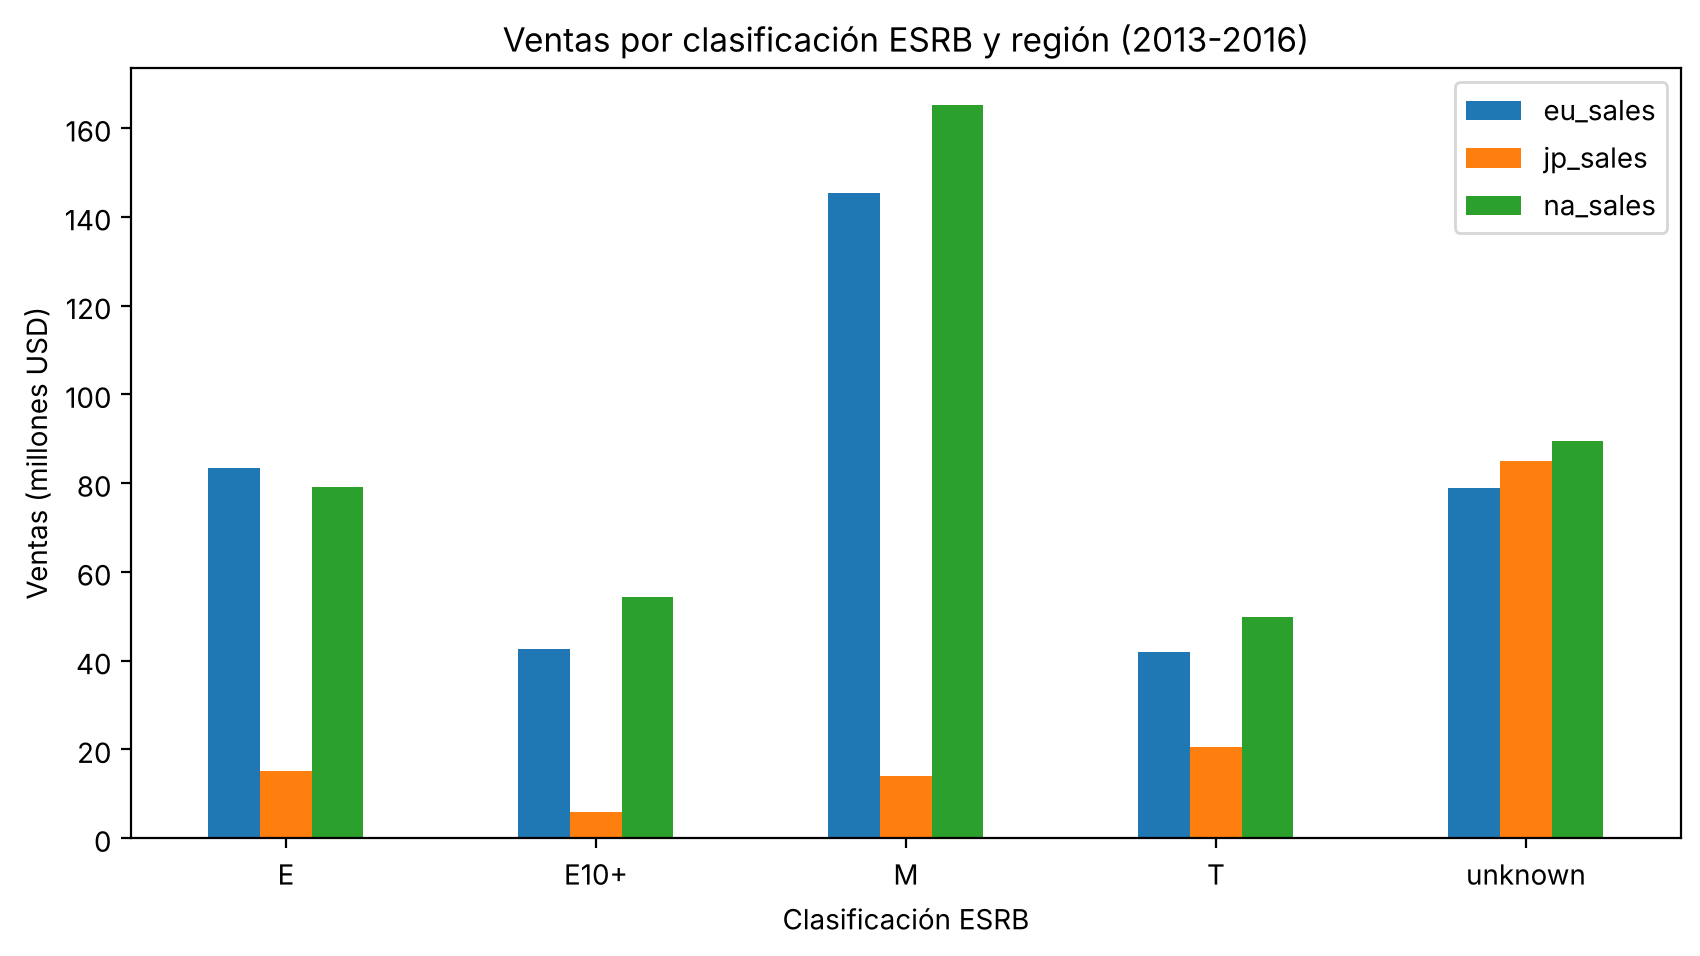

In [49]:
ventas_rating.plot(kind='bar', figsize=(10, 5))
plt.title('Ventas por clasificación ESRB y región (2013-2016)')
plt.xlabel('Clasificación ESRB')
plt.ylabel('Ventas (millones USD)')
plt.xticks(rotation=0)
plt.show()

- En **NA y UE**, los juegos **M** son los que más venden.
- En **JP**, la mayor parte de las ventas corresponde a juegos **sin clasificación (`unknown`)**, porque la ESRB no clasifica los juegos que solo se publican en Japón.
- La clasificación ESRB sí se relaciona con las ventas en NA y UE, pero no es útil para nada en **el mercado japonés**.


## Paso 5. Pruebas de hipótesis

- **Nivel de significancia:** `alpha = 0.05`, el valor estándar.
- **Prueba:** `st.ttest_ind`, porque se comparan las medias de **dos muestras independientes**.
- **`equal_var`:** primero se comparan las varianzas con `np.var`. Si son diferentes, se usa `equal_var=False`.
- Los `NaN` de `user_score` se excluyen con `dropna()`.


### 5.1 Xbox One vs PC

- **H₀:** las calificaciones promedio de los usuarios de Xbox One y PC son iguales.
- **H₁:** las calificaciones promedio de los usuarios de Xbox One y PC son diferentes.


In [50]:
xone = df_actual[df_actual['platform'] == 'XOne']['user_score'].dropna()
pc = df_actual[df_actual['platform'] == 'PC']['user_score'].dropna()

print('Media XOne:', round(xone.mean(), 2),
      '| Varianza:', round(np.var(xone), 2))
print('Media PC:  ', round(pc.mean(), 2), '| Varianza:', round(np.var(pc), 2))

Media XOne: 6.52 | Varianza: 1.9
Media PC:   6.27 | Varianza: 3.02


In [51]:
alpha = 0.05

results = st.ttest_ind(xone, pc, equal_var=False)
print('valor p:', results.pvalue)

if results.pvalue < alpha:
    print('Rechazamos la hipótesis nula')
else:
    print('No hay evidencia suficiente para rechazar la hipótesis nula')

valor p: 0.1475959401343046
No hay evidencia suficiente para rechazar la hipótesis nula


**Resultado:** las varianzas son diferentes 1.90 frente a 3.02 por eso se usa `equal_var=False`. El valor p aprox 0.15 es mayor que alpha, así que **no puedo rechazar H₀**: no hay evidencia de que los usuarios califiquen distinto los juegos de Xbox One y de PC.


### 5.2 Acción vs Deportes

- **H₀:** las calificaciones promedio de los usuarios de los géneros Acción y Deportes son iguales.
- **H₁:** las calificaciones promedio de los usuarios de los géneros Acción y Deportes son diferentes.


In [52]:
action = df_actual[df_actual['genre'] == 'Action']['user_score'].dropna()
sports = df_actual[df_actual['genre'] == 'Sports']['user_score'].dropna()

print('Media Action:', round(action.mean(), 2),
      '| Varianza:', round(np.var(action), 2))
print('Media Sports:', round(sports.mean(), 2),
      '| Varianza:', round(np.var(sports), 2))

Media Action: 6.84 | Varianza: 1.76
Media Sports: 5.24 | Varianza: 3.16


In [53]:
results = st.ttest_ind(action, sports, equal_var=False)
print('valor p:', results.pvalue)

if results.pvalue < alpha:
    print('Rechazamos la hipótesis nula')
else:
    print('No podemos rechazar la hipótesis nula')

valor p: 1.4460039700703936e-20
Rechazamos la hipótesis nula


**Resultado:** el valor p es prácticamente 0, mucho menor que alpha, así que **rechazamos H₀**. Las calificaciones de los usuarios son diferentes entre géneros: Action es diferente de Sports.


## Paso 6. Conclusión general

**Preparación de datos:** se normalizaron los nombres de las columnas, se corrigieron los tipos (`year_of_release`, `user_score`, y el valor `'tbd'` tratado como `NaN`), se eliminaron duplicados y registros sin año, y los ausentes de `rating` se marcaron como `unknown`. Las calificaciones se dejaron como `NaN` para no sesgar las correlaciones ni las pruebas. Además se elimina un valor inconsistente donde no concuerda con que el **DS** fue lanzado en 2004

**Período de análisis:** una plataforma vive unos 6-7 años y llega a su pico en 3-5. Por eso se trabajó con **2013-2016**, el período de la generación actual de consolas.

**Hallazgos clave para la campaña 2017:**

1. **Plataformas:** **PS4** y **Xbox One** son las únicas que crecen y concentran las ventas. PS3, X360, Wii y DS están en declive. En Japón conviene incluir **3DS**.

2. **Géneros:** **Shooter** es el más rentable por juego. **Action** vende más en total por volumen de lanzamientos. Sports y Role-Playing también son fuertes.

3. **Reseñas:** la nota de los **críticos** tiene una relación moderada con las ventas, alrededor del 40%. La de los **usuarios** casi no influye y es una relación indirecta.

4. **Regiones:**
   - **NA:** PS4/XOne, Action/Shooter, juegos M.
   - **UE:** perfil parecido, con PS4 como líder.
   - **JP:** mercado distinto, con 3DS, abarcan más las consolas portátiles y el Role-Playing.

5. **Hipótesis:** los usuarios califican igual los juegos de Xbox One y de PC, pero califican de forma distinta Action y Sports.

**Recomendación para 2017:**

- En NA y UE priorizar la publicidad de juegos de **PS4 y Xbox One** en los géneros **Shooter, Action y Sports**.
- Para Japón, conviene una campaña separada centrada en **3DS y Role-Playing**.
